# M06 · Théorie de l'information — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m06_information/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M06.1 à M06.9, M06.12, M06.13 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M06.16 | Entropies conjointe et conditionnelle d'un tableau · `joint_entropy, conditional_entropy` | 🔨 | ★ | 20 |
|  | M06.17 | L'information mutuelle · `mutual_information` | 🔨 | ★ | 15 |
|  | M06.18 | Codes préfixes et somme de Kraft · `kraft_sum, is_prefix_code` | 🔨 | ★ | 15 |
|  | M06.19 | L'écart de Jensen d'une loi discrète · `jensen_gap` | 🔨 | ★ | 15 |
|  | M06.20 | `sklearn.metrics.mutual_info_score` contre ta fonction, en nats | 📦 | ★ | 15 |
| B | M06.21 | Prédire : l'information mutuelle de X et X³, de X et X² | 🔮 | ★ | 10 |
|  | M06.22 | Estimer une entropie à partir d'un échantillon : le biais des petits échantillons | 🔬 | ★★ | 20 |
|  | M06.23 | Un diagramme de l'information : H(X), H(Y), H(X \| Y), I(X ; Y) | 🎨 | ★ | 20 |
| C | M06.24 | Chasse à l'erreur : log en base 10, 0 log 0, KL à l'envers | 🐛 | ★ | 15 |
|  | M06.25 | Calculer 0 log 0 proprement (`scipy.special.xlogy`) | 🛠️ | ★ | 10 |
|  | M06.26 | Défi : localiser une panne parmi 100 serveurs en un minimum de questions | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : information et entropie, entropies conjointe et conditionnelle, information mutuelle, cross-entropy et KL, inégalité de Jensen, Kraft, longueur moyenne d'un code, log loss d'un classifieur, choix d'une feature.
- Écrire les six fonctions de `mymath/info.py` et les tester, puis utiliser scikit-learn.
- Prédire l'information mutuelle de $X$ avec $X^3$ et $X^2$, mesurer le biais de l'entropie estimée, dessiner le diagramme de l'information, chasser des erreurs, calculer $0 \log 0$ proprement, localiser une panne en un minimum de questions.

**Rappel express.** $H(X) = -\sum p \log_2 p$ ; $H(X, Y) = H(X) + H(Y \mid X)$ ; $I(X ; Y) = H(Y) - H(Y \mid X) = H(X) + H(Y) - H(X, Y) \ge 0$ ; $H(p, q) = -\sum p \log_2 q = H(p) + \mathrm{KL}(p \,\|\, q)$ ; Jensen : $\mathbb{E}[f(X)] \ge f(\mathbb{E}[X])$ pour $f$ convexe ; Kraft : $\sum 2^{-\ell_i} \le 1$ ; le meilleur code préfixe vérifie $H \le \bar{L} < H + 1$ ; 1 nat $\approx 1{,}443$ bit.

## Partie 0 · Vérifier tes exercices papier (✏️ M06.1 à M06.9, 🔗 M06.12 et M06.13)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"5/9"` ;
- une liste `[-1.5, 2.5]`, `True` / `False`, ou une lettre ou un nom entre guillemets, `"B"`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math
from fractions import Fraction


def H(*probs):
    """Entropy in bits of a law given by its probabilities (0 log 0 counts as 0)."""
    return -sum(p * math.log2(p) for p in probs if p > 0)


def MI(counts):
    """Mutual information in bits of the joint law given by a table of counts (rows: the feature, columns: Y)."""
    total = sum(map(sum, counts))
    rows = [sum(row) / total for row in counts]
    cols = [sum(col) / total for col in zip(*counts)]
    return sum(c / total * math.log2(c / total / (rows[i] * cols[j]))
               for i, row in enumerate(counts) for j, c in enumerate(row) if c > 0)


H1 = H(0.55, 0.35, 0.07, 0.03)                                                  # M06.1
INFO_SUM_1 = -sum(math.log2(p) for p in (0.55, 0.35, 0.07, 0.03))
HMAX_2 = H(0.45, 0.55 / 3, 0.55 / 3, 0.55 / 3)                                  # M06.2 e)
HYX_5 = 9 / 16 * H(1 / 9, 8 / 9) + 3 / 16 * H(1 / 3, 2 / 3) + 1 / 4 * 0        # M06.5: H(Y | X)
P_6 = [1 / 4, 1 / 4, 1 / 4, 1 / 8, 1 / 8]                                       # M06.6
Q_6 = [1 / 2, 1 / 4, 1 / 16, 1 / 16, 1 / 8]
CROSS_6 = sum(pi * -math.log2(qi) for pi, qi in zip(P_6, Q_6))                  # H(p, q)
P_9 = [0.4, 0.2, 0.15, 0.1, 0.1, 0.05]                                          # M06.9
LENGTHS_9 = [2, 3, 2, 3, 3, 3]                                                  # the code {00, 100, 01, 101, 110, 111}
L_9 = sum(pi * li for pi, li in zip(P_9, LENGTHS_9))
LOSS_12 = -sum(math.log(p) for p in (0.5, 0.8, 0.35, 0.9, 0.45)) / 5            # M06.12, in nats

**Ex M06.1 — L'information d'événements et l'entropie d'une loi à quatre issues**

In [3]:
wbm.record("M06.1a", [-math.log2(0.55), -math.log2(0.35), -math.log2(0.07), -math.log2(0.03)], decimals=2, mistakes={"la question demande des bits : log₂ x = ln x / ln 2, pas ln": [-math.log(0.55), -math.log(0.35), -math.log(0.07), -math.log(0.03)], "l'information d'un événement de probabilité p < 1 est positive : c'est −log₂ p": [math.log2(0.55), math.log2(0.35), math.log2(0.07), math.log2(0.03)]})
wbm.record("M06.1b", H1, decimals=3, mistakes={"l'entropie est la moyenne des informations, pondérée par les probabilités, pas leur somme": INFO_SUM_1, "l'entropie pondère chaque information par la probabilité de son issue, pas par 1/4": INFO_SUM_1 / 4, "tes informations, arrondies à 2 décimales, décalent la moyenne : pour b), garde au moins 4 décimales pour chaque information": sum(p * round(-math.log2(p), 2) for p in (0.55, 0.35, 0.07, 0.03)), "la question demande des bits : log₂ x = ln x / ln 2, pas ln": H1 * math.log(2)})
wbm.record("M06.1c", H1 * math.log(2), decimals=2, mistakes={"la question demande des nats : convertis les bits en nats (fiche §1)": H1, "1 nat vaut plus qu'un bit : le nombre de nats est plus petit que le nombre de bits": H1 / math.log(2)})
wbm.record("M06.1d", -math.log2(0.55) - math.log2(0.03), decimals=3, mistakes={"les informations d'événements indépendants s'additionnent": math.log2(0.55) * math.log2(0.03), "la probabilité de deux événements indépendants est le produit des probabilités, pas leur somme": -math.log2(0.58)})
wbm.record("M06.1e", H(0.55, 0.35, 0.1), decimals=3, mistakes={"c'est l'entropie de la loi à quatre issues : regroupe d'abord les deux erreurs en une seule issue, de probabilité la somme des deux": H1, "chaque terme −p log₂ p arrondi à 3 décimales décale le dernier chiffre de la somme : garde au moins 4 décimales par terme": 1.336})
wbm.record("M06.1f", 2 * H1, decimals=3, mistakes={"c'est l'entropie d'une seule requête : le couple des codes de deux requêtes a seize issues possibles": H1})

WBM_ANSWER {"decimals": 2, "element_coarse": [["ee8a4952f5c84b2f9f6851e4a016f76bd3fb755d67ab8bbe840ce28a6a66c145"], ["4ce30c195d166ced9e5161afecd681cb84bb436874a1e92193b51751e8825c2c"], ["536332df36d2cfeb655cf3c5113cf1230eee7a77f9f1c03ce3b9b314cd5e10c8"], ["e7e1b555c6e89085ccfcba930e8cc2c50496f4103f76e157be89c2e67754eae1"]], "element_coarse_any": [["07d8edd3555eb4454a57338b1458547d95d1de2b4d87f9b89745eead5a4a9708"], ["48c2a863ca79af66660a0813f0153a1927b611d8b20e45640f8ad927d04a3603"], ["58669e2c319a8a4ef413f3decd5d3044c6086858a8dd9ef6b1fc6a75d07fcba7"], ["5497c72b0867512511c41ccade5cae584f55e5a2abaaa615554c9b2ffd230721"]], "element_hashes": ["cacd2d5f276167e8714378c76e1b40c610d4dcc321875844464b1387f223dcdb", "2a7c784086c8cf567172ecc92d4f77770f8b3e8352207ad28e4c421c97e85848", "05b4fe30ef675958dc890ef6ba630a90ba3af68204226267301bd61a69353f66", "6c08f4e5c617142b6f051657536ebf72984518a5bb4eda5114900fa3c9d31695"], "hash": "a8a635df1ed8b7d4a92cc6d0cf348be9789b2143ff7753cf49e1396791635631", "

**Ex M06.2 — L'entropie maximale : comparer des lois à quatre issues**

In [4]:
wbm.record("M06.2a", H(0.45, 0.3, 0.15, 0.1), decimals=3, mistakes={"la question demande des bits : log₂ x = ln x / ln 2, pas ln": H(0.45, 0.3, 0.15, 0.1) * math.log(2)})
wbm.record("M06.2b", H(0.4, 0.3, 0.15, 0.15), decimals=3, mistakes={"la question demande des bits : log₂ x = ln x / ln 2, pas ln": H(0.4, 0.3, 0.15, 0.15) * math.log(2), "chaque terme −p log₂ p arrondi à 3 décimales décale le dernier chiffre de la somme : garde au moins 4 décimales par terme": 1.872})
wbm.record("M06.2c", H(0.45, 0.3, 0.25), decimals=2, mistakes={"la question demande des bits : log₂ x = ln x / ln 2, pas ln": H(0.45, 0.3, 0.25) * math.log(2)})
wbm.record("M06.2d", 2 - H(0.45, 0.3, 0.15, 0.1), decimals=3, mistakes={"l'entropie maximale sur n issues n'est pas n : relis « Ses valeurs extrêmes » (fiche §2)": 4 - H(0.45, 0.3, 0.15, 0.1), "ce qu'il manque est le maximum moins H(A) : un nombre positif": H(0.45, 0.3, 0.15, 0.1) - 2, "la question demande l'écart entre ce maximum et H(A), pas l'une des deux entropies": {2, H(0.45, 0.3, 0.15, 0.1)}})
wbm.record("M06.2e", HMAX_2, decimals=3, mistakes={"la contrainte fixe la probabilité de la première issue : la loi uniforme sur quatre issues ne la respecte pas": 2})
wbm.record("M06.2f", HMAX_2 * math.log(2), decimals=2, mistakes={"la question demande des nats : convertis les bits en nats (fiche §1)": HMAX_2, "1 nat vaut plus qu'un bit : le nombre de nats est plus petit que le nombre de bits": HMAX_2 / math.log(2)})

WBM_ANSWER {"coarse_any": {"0": ["4639142f2454be10a02569931904dd73fcb5776af284760f20a90a359cfb0db8"]}, "coarser": {"1": ["586bfb98a0cc05305feaf941428a6936cc82a3b8e6b18e2e4521ce924504c60c"]}, "decimals": 3, "hash": "11a6b20215f1fe2a347742141f534ee7b2b5c0b277dd3514999397f828e682b3", "hash_coarse": "cae8b65c474201ee5ea0cfda335f68da1b362f30ce3ae305d3e52af69935a2a2", "id": "M06.2a", "kind": "float", "magnitude": 0, "mistakes": {"c0d5cda2a5c457b394fdb02035ec18485203fbe0172a1f009d4d2f8d222cb331": "la question demande des bits : log₂ x = ln x / ln 2, pas ln"}, "sign": 1}
📝 Ex M06.2a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"0": ["56a4ca5c732070c2f133e6fdcfc87ff6301d046d6da8f0cb9b0d41817b8a173a"]}, "coarser": {"1": ["f6ad7b078978c7992e52bb59ab89023271daee4a21b1295da99fb2b6f2e49b1f"]}, "decimals": 3, "hash": "310176f21ee54fc7adf6c009780c6bbbdc6db1dc016ab1769992cdc0b99612ce", "hash_coarse": "e8e283184bff47c52cbb15562d7d6f988bd00d643abf164e40d91f422462d0f2", "id": "M0

**Ex M06.3 — Entropies conjointe et conditionnelle d'un tableau 2 × 3**

In [5]:
wbm.record("M06.3a", H(0.4, 0.18, 0.21, 0.21), decimals=3, mistakes={"H(X, Y) se calcule sur les cases du tableau : elle ne vaut H(X) + H(Y) que pour des variables indépendantes": H(0.4, 0.6) + H(0.58, 0.21, 0.21)})
wbm.record("M06.3b", H(0.3, 0.35, 0.35), decimals=3, mistakes={"divise les cases de la ligne par P(X = payant) : la loi conditionnelle doit sommer à 1": H(0.18, 0.21, 0.21), "divise d'abord les cases de la ligne par P(X = payant), puis calcule l'entropie de cette loi": H(0.18, 0.21, 0.21) / 0.6})
wbm.record("M06.3c", 0.6 * H(0.3, 0.35, 0.35), decimals=3, mistakes={"H(Y | X) est une moyenne sur les valeurs de X, pondérée par leurs probabilités : la ligne « gratuit » compte aussi": H(0.3, 0.35, 0.35), "pondère l'entropie de chaque ligne par sa probabilité P(X = x)": H(0.3, 0.35, 0.35) / 2, "ta valeur est H(X) ; la question demande H(Y | X)": H(0.4, 0.6)})
wbm.record("M06.3d", H(0.58, 0.21, 0.21), decimals=2, mistakes={"ta valeur est H(X) ; Y est la variable des colonnes": H(0.4, 0.6)})
wbm.record("M06.3e", H(0.4, 0.18, 0.21, 0.21) - H(0.58, 0.21, 0.21), decimals=2, mistakes={"ta valeur est H(Y | X) ; la question demande H(X | Y), l'entropie de X quand Y est connue": 0.6 * H(0.3, 0.35, 0.35), "ta valeur est I(X ; Y) ; la question demande H(X | Y)": H(0.4, 0.6) - (H(0.4, 0.18, 0.21, 0.21) - H(0.58, 0.21, 0.21))})
wbm.record("M06.3f", H(0.3, 0.35, 0.35) - H(0.58, 0.21, 0.21), decimals=2, mistakes={"l'écart demandé est H(Y | X = payant) moins H(Y), dans cet ordre": H(0.58, 0.21, 0.21) - H(0.3, 0.35, 0.35)})

WBM_ANSWER {"coarse_any": {"0": ["268bbf8bece26b36446ff666178a872c0e3f157cc739c972b2f04229ef7584c5"]}, "coarser": {"1": ["ee44c9c43c827b4dc787b775e0e2c5d4bfbef5c87633752c6fa7ee0996d6ee70"]}, "decimals": 3, "hash": "456f84b154d3280117b56f39e2523c721967b32ebf5f45360424a913e63ddb45", "hash_coarse": "ed710eb1c695ffa0408daf90c82e6ca3e8eaeb3c273d627d724ccccc8f617550", "id": "M06.3a", "kind": "float", "magnitude": 0, "mistakes": {"f747d92576491c1be7535cf741912e3a4d55761f60a9e254c3f8a5da3f263cd3": "H(X, Y) se calcule sur les cases du tableau : elle ne vaut H(X) + H(Y) que pour des variables indépendantes"}, "sign": 1}
📝 Ex M06.3a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"0": ["10cf889b9535ebd2888d8ee44699a36516e8fde8b60e15cc3af44c4cea5aa7ba"]}, "coarser": {"1": ["c89e2b0af7660e64afa95ee3003c25d0200a4fb15519dd1ecd76b38aead2fa48"]}, "decimals": 3, "hash": "f78b4eccd2856a71dc8dc13459a835f7df4b870c6bfc87bd6a5f1eef0009fbad", "hash_coarse": "07a82e266897d4d0a53f72c4c5ed

**Ex M06.4 — La règle de la chaîne de l'entropie, vérifiée**

In [6]:
wbm.record("M06.4a", 1)
wbm.record("M06.4b", H(0.7, 0.3), decimals=3, mistakes={"divise les cases de la ligne par P(X = e-mail) : la loi conditionnelle doit sommer à 1": H(0.35, 0.15), "divise d'abord les cases de la ligne par P(X = e-mail), puis calcule l'entropie de cette loi": H(0.35, 0.15) / 0.5})
wbm.record("M06.4c", H(0.4, 0.6), decimals=3, mistakes={"divise les cases de la ligne par P(X = SMS) : la loi conditionnelle doit sommer à 1": H(0.2, 0.3), "divise d'abord les cases de la ligne par P(X = SMS), puis calcule l'entropie de cette loi": H(0.2, 0.3) / 0.5})
wbm.record("M06.4d", (H(0.7, 0.3) + H(0.4, 0.6)) / 2, decimals=3, mistakes={"H(Y | X) est une moyenne des entropies des lignes, pondérée par P(X = x), pas leur somme": H(0.7, 0.3) + H(0.4, 0.6)})
wbm.record("M06.4e", H(0.35, 0.15, 0.2, 0.3), decimals=3, mistakes={"H(X, Y) ne vaut H(X) + H(Y) que si X et Y sont indépendantes : calcule-la sur les quatre cases": 1 + H(0.55, 0.45)})
wbm.record("M06.4f", H(0.55, 0.45), decimals=3, mistakes={"la loi de Y : additionne les cases de chaque colonne": 1})
wbm.record("M06.4g", H(0.35, 0.15, 0.2, 0.3) - H(0.55, 0.45), decimals=3, mistakes={"ta valeur est H(Y | X) ; la question demande H(X | Y), l'entropie de X quand Y est connue": (H(0.7, 0.3) + H(0.4, 0.6)) / 2, "ta valeur est I(X ; Y) ; la question demande H(X | Y)": 1 - (H(0.35, 0.15, 0.2, 0.3) - H(0.55, 0.45))})

WBM_ANSWER {"hash": "6379b1ec409dc8bb206e4ad21a76e26f6f07d89506fd2c3ba1216fe48f0f3cbb", "id": "M06.4a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M06.4a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["77374839ac40719cfafcdc7585802acf6d74e3ecd8adb387374e7687eb1bd1a4"], "1": ["834d8313a48364fedc3838c0d8343d7911b62d2c619c869b6cb72eb8f5addcac"]}, "decimals": 3, "hash": "c05890e0c50a87cb1f5690794d6d24d1b56459e1979d4eb6cfd02a266481a4a6", "hash_coarse": "7d2db9f90b755a13f9b66a9884a44c50e1cfd37b7ce0b4cfdd322a3f81d49670", "id": "M06.4b", "kind": "float", "magnitude": -1, "mistakes": {"2412d8d77c413895ef4105c3d2d65161e30e7c270268a4ed69392d61cc3a591b": "divise les cases de la ligne par P(X = e-mail) : la loi conditionnelle doit sommer à 1", "8a1a5f54067021a67d9175940d89a3e524a10ca933b88369a718670242165d5d": "divise d'abord les cases de la ligne par P(X = e-mail), puis calcule l'entropie de cette loi"}, "sign": 1}
📝 Ex M06.4b : réponse enregistrée (float, 3 décimales).
WBM_ANSW

**Ex M06.5 — L'information mutuelle de deux variables**

In [7]:
wbm.record("M06.5a", Fraction(7, 16), kind="fraction", simplified=True, mistakes={"« freine » est la première colonne": "9/16"})
wbm.record("M06.5b", H(7 / 16, 9 / 16), decimals=3)
wbm.record("M06.5c", H(1 / 9, 8 / 9), decimals=3, mistakes={"divise les cases de la ligne par P(X = vert) : la loi conditionnelle doit sommer à 1": H(1 / 16, 1 / 2), "divise d'abord les cases de la ligne par P(X = vert), puis calcule l'entropie de cette loi": H(1 / 16, 1 / 2) / (9 / 16)})
wbm.record("M06.5d", HYX_5, decimals=3, mistakes={"H(Y | X) est une moyenne des entropies des lignes, pondérée par P(X = x), pas leur somme": H(1 / 9, 8 / 9) + H(1 / 3, 2 / 3), "pondère l'entropie de chaque ligne par sa probabilité P(X = x)": (H(1 / 9, 8 / 9) + H(1 / 3, 2 / 3)) / 3})
wbm.record("M06.5e", H(7 / 16, 9 / 16) - HYX_5, decimals=2, mistakes={"I(X ; Y) est la baisse de l'incertitude sur Y quand on apprend X : elle est positive ou nulle": HYX_5 - H(7 / 16, 9 / 16)})
wbm.record("M06.5f", H(9 / 16, 3 / 16, 1 / 4), decimals=3)
wbm.record("M06.5g", H(9 / 16, 3 / 16, 1 / 4) - (H(7 / 16, 9 / 16) - HYX_5), decimals=2, mistakes={"ta valeur est H(Y | X) ; la question demande H(X | Y), l'entropie de X quand Y est connue": HYX_5})
wbm.record("M06.5h", False, mistakes={"compare p(x, y) avec p(x) p(y), case par case": True})

WBM_ANSWER {"hash": "c2e330302c66521d93bb252ac738a90b6b304e40bdeb94a966719dc57e231cd4", "id": "M06.5a", "kind": "fraction", "mistakes": {"05fe5741fcea6e05e585c40db1d1badf586f6750bc7bf200f88e1f16b28194af": "« freine » est la première colonne"}, "sign": 1, "simplified": true}
📝 Ex M06.5a : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"0": ["ad245dedb38fe2931854c7f3f614578c7101993dcca912bf2e11d31b6081e7e0"], "1": ["bf30e1f7e60dae3e0aa854c6952f22573150a189cebe44f837a7276a30127f17"]}, "decimals": 3, "hash": "9163defb200ed71a1150f7f2e02584316693405735e62d1cf527a7483af17cc0", "hash_coarse": "ebbf293d76f8a7f8800d438f323f4e2c1b90eb4c9ec7b94afeb33245c6fc3a34", "id": "M06.5b", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex M06.5b : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"0": ["3dd51ef2f0f6a3d5a51d7921baf8513b63237b9dcd72741e63dc40034f68bf88"], "1": ["8c012c885136bc289ebd0098d356f51f5f4006ab547097c6396e425591443460"]}, "decimals": 3, "hash": "e9fa13f3

**Ex M06.6 — Cross-entropy et KL en bits perdus : un code fait pour la mauvaise loi**

In [8]:
wbm.record("M06.6a", H(*P_6), decimals=2, mistakes={"c'est l'entropie de l'ancienne loi q ; la question demande celle de p": H(*Q_6)})
wbm.record("M06.6b", 1, mistakes={"le compresseur a été réglé sur l'ancienne loi : la longueur est −log₂ q": 2})
wbm.record("M06.6c", CROSS_6, decimals=3, mistakes={"H(p, q) pondère les longueurs −log₂ q par les probabilités d'aujourd'hui, p": H(*Q_6), "H(p, q) utilise les longueurs du compresseur, −log₂ q, pas −log₂ p": H(*P_6), "c'est H(q, p) : les poids sont les probabilités d'aujourd'hui, p, et les longueurs celles du compresseur": sum(qi * -math.log2(pi) for pi, qi in zip(P_6, Q_6))})
wbm.record("M06.6d", CROSS_6 - H(*P_6), decimals=3, mistakes={"la divergence KL est positive ou nulle": H(*P_6) - CROSS_6, "c'est KL(q ‖ p) : l'ordre des deux lois compte": sum(qi * math.log2(qi / pi) for pi, qi in zip(P_6, Q_6))})
wbm.record("M06.6e", 375, mistakes={"c'est la longueur totale avec ce compresseur ; la question demande les bits perdus par rapport au meilleur code": 2625, "c'est la longueur totale avec le meilleur code ; la question demande les bits perdus": 2250})
wbm.record("M06.6f", (CROSS_6 - H(*P_6)) * math.log(2), decimals=3, mistakes={"la question demande des nats : convertis les bits en nats (fiche §1)": CROSS_6 - H(*P_6), "1 nat vaut plus qu'un bit : le nombre de nats est plus petit que le nombre de bits": (CROSS_6 - H(*P_6)) / math.log(2)})
wbm.record("M06.6g", 0.25 * math.log2(0.25 / 0.5), decimals=2, mistakes={"le terme d'un type est p log₂(p / q) : p devant, et p au numérateur": 0.5 * math.log2(0.5 / 0.25), "p₁ / q₁ est-il plus grand ou plus petit que 1 ? Le signe du logarithme en dépend": 0.25})

WBM_ANSWER {"alt_coarse": ["616d88e5106738dd395cf942bb2e5f0bb22be0e773f69198862d112ba7131588"], "coarse_any": {"0": ["22a7876ed7e895e4ee855fc5bd13baa36533af89a9bab1d3785bed2df9d79120"]}, "decimals": 2, "hash": "390e960c6a46dd21ab4de78f512c05b185856ae4ce1b7708a87232e03d7ce922", "hash_coarse": "b64009ba08a6b0525fb2b1bbef5e04972eb5f680d8a325762969e21fa5f75d1a", "id": "M06.6a", "kind": "float", "magnitude": 0, "mistakes": {"40553677b1cc1d67020b00280aaf72e979ab454f24ebc8352737a9575a3b275b": "c'est l'entropie de l'ancienne loi q ; la question demande celle de p", "9a5c1dbb626661493929428756fd4611348d7eeed1c9c8a4539bac0b4035d693": "c'est l'entropie de l'ancienne loi q ; la question demande celle de p"}, "sign": 1}
📝 Ex M06.6a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"hash": "2b8bfc914e7f95f4f593d35e0eb86c9e8984164fdb16fdb065602ffe2b6bfa2e", "id": "M06.6b", "kind": "int", "magnitude": 0, "mistakes": {"a68f73db01b51424f11e6fe8ce42cef3b597ae32dcfd68943bb24e7cf038e2c0": "le compres

**Ex M06.7 — L'inégalité de Jensen sur trois exemples**

In [9]:
wbm.record("M06.7a", 3)
wbm.record("M06.7b", 11, mistakes={"E[X²] n'est pas (E[X])² : c'est la moyenne des carrés": 9})
wbm.record("M06.7c", 2, mistakes={"l'écart de Jensen est E[f(X)] − f(E[X]), dans cet ordre": -2})
wbm.record("M06.7d", (1 + math.e) / 2 - math.exp(0.5), decimals=4, mistakes={"l'écart de Jensen est E[f(X)] − f(E[X]), dans cet ordre": math.exp(0.5) - (1 + math.e) / 2})
wbm.record("M06.7e", (math.log2(1) + math.log2(4)) / 2, decimals=1)
wbm.record("M06.7f", math.log2(2.5), decimals=4, mistakes={"la question demande log₂, pas ln": math.log(2.5)})
wbm.record("M06.7g", 1 - math.log2(2.5), decimals=4, mistakes={"l'écart de Jensen est E[f(X)] − f(E[X]), dans cet ordre": math.log2(2.5) - 1})

WBM_ANSWER {"hash": "04446427e14f1077e5ea3502fb8bd5decd03cb466e0e113f3e6f43c9c90bd1f7", "id": "M06.7a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M06.7a : réponse enregistrée (int).
WBM_ANSWER {"hash": "1f4b2f290a7747621d1d943031f686cee0bf82150a01dcb80c256a72d8990672", "id": "M06.7b", "kind": "int", "magnitude": 1, "mistakes": {"393d550ed96bf8b57932c155fffb2b884ac21775d8249915835d6bdacaecfcf6": "E[X²] n'est pas (E[X])² : c'est la moyenne des carrés"}, "sign": 1}
📝 Ex M06.7b : réponse enregistrée (int).
WBM_ANSWER {"hash": "55a2815fd60c244decdb931d739fadacfbf7176930c12e585378e0c8508ccdd6", "id": "M06.7c", "kind": "int", "magnitude": 0, "mistakes": {"083e25da582ec5bb753b64ee2b17e9de2c5cfc29259e04db61d4e25a16bf55fc": "l'écart de Jensen est E[f(X)] − f(E[X]), dans cet ordre"}, "sign": 1}
📝 Ex M06.7c : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"1": ["a0e88d73197fa04d1633c6aa367e8e79e76f209d2321563fbae8dd3ffeed1b9a"]}, "coarser": {"2": ["09c871f3f3188427bc79bdcb28a727160caf2

**Ex M06.8 — Kraft : ces longueurs de code sont-elles possibles ?**

In [10]:
wbm.record("M06.8a", Fraction(15, 16), kind="fraction", simplified=True, mistakes={"un mot de longueur ℓ compte pour 2^(−ℓ), pas pour 1/ℓ": "25/12"})
wbm.record("M06.8b", Fraction(17, 16), kind="fraction", simplified=True)
wbm.record("M06.8c", Fraction(19, 16), kind="fraction", simplified=True)
wbm.record("M06.8d", Fraction(1, 1), kind="fraction", simplified=True)
wbm.record("M06.8e", Fraction(1, 1), kind="fraction", simplified=True, mistakes={"l'alphabet a trois symboles : un mot de longueur ℓ compte pour 3^(−ℓ)": "7/4"})
wbm.record("M06.8f", 2, mistakes={"les deux mots déjà là prennent chacun leur part de la somme de Kraft": {4, 6}})
wbm.record("M06.8g", False, mistakes={"un des mots est-il le début d'un autre ?": True})
wbm.record("M06.8h", Fraction(1, 1), kind="fraction", simplified=True)

WBM_ANSWER {"hash": "9c6c7700d6b28fda478707d11a2fc2c36716bd7d3ee449d99930252740a0e870", "id": "M06.8a", "kind": "fraction", "mistakes": {"6abe5d0f9f90c406b8f4138c54e5540f82f877b2feb0ecca64d48606b75b090f": "un mot de longueur ℓ compte pour 2^(−ℓ), pas pour 1/ℓ"}, "sign": 1, "simplified": true}
📝 Ex M06.8a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "95a937cdc5376bea190187ddb444a613029e61877df8a85dee4bbdb0c9a46b7c", "id": "M06.8b", "kind": "fraction", "sign": 1, "simplified": true}
📝 Ex M06.8b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "5750691b8da94c9f15d94535ff555cdfb2b6264caad6f07fb27fd7dcc7264c3b", "id": "M06.8c", "kind": "fraction", "sign": 1, "simplified": true}
📝 Ex M06.8c : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "d20592b035f788823ffff8d5fdbae44a6284d8ae1982637f17691c3d0a09797b", "id": "M06.8d", "kind": "fraction", "sign": 1, "simplified": true}
📝 Ex M06.8d : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "c6d93e98c4fd8c15f383de4326a5f111c0d7

**Ex M06.9 — La longueur moyenne d'un code, comparée à l'entropie**

In [11]:
wbm.record("M06.9a", H(*P_9), decimals=3, mistakes={"la question demande des bits : log₂ x = ln x / ln 2, pas ln": H(*P_9) * math.log(2)})
wbm.record("M06.9b", L_9, decimals=2, mistakes={"la longueur moyenne pondère chaque longueur par la probabilité de son symbole": sum(LENGTHS_9) / 6, "le code donne ses mots aux symboles dans l'ordre de l'énoncé : associe chaque longueur à la probabilité de son symbole": sum(pi * li for pi, li in zip(P_9, sorted(LENGTHS_9)))})
wbm.record("M06.9c", 3, mistakes={"avec ce nombre de chiffres binaires, combien de mots différents peut-on écrire ?": 2})
wbm.record("M06.9d", [2, 3, 3, 4, 4, 5], mistakes={"arrondis −log₂ pᵢ à l'entier supérieur, pas à l'entier le plus proche": [1, 2, 3, 3, 3, 4], "arrondis −log₂ pᵢ à l'entier supérieur, pas à l'entier inférieur": [1, 2, 2, 3, 3, 4]})
wbm.record("M06.9e", Fraction(21, 32), kind="fraction", simplified=True)
wbm.record("M06.9f", sum(pi * li for pi, li in zip(P_9, [2, 3, 3, 4, 4, 5])), decimals=2)
wbm.record("M06.9g", L_9 - H(*P_9), decimals=3, mistakes={"l'écart est la longueur moyenne moins l'entropie, dans cet ordre": H(*P_9) - L_9})
wbm.record("M06.9h", sum(pi * li for pi, li in zip(P_9, [1, 3, 3, 3, 4, 4])), decimals=2, mistakes={"la longueur moyenne pondère chaque longueur par la probabilité de son symbole": 18 / 6})

WBM_ANSWER {"coarse_any": {"0": ["676b40a82965c938b3198ef36562efa507318383360d0aabd8042a0c7154ce72"]}, "coarser": {"1": ["07f20867471592bcfac8417e57d64cabe166b4b751d41ec11260e4dd175e1c23"]}, "decimals": 3, "hash": "2df7fdf14fd014869e5c665aaf9a06c4b27e25810406b81bd4bab943904fac02", "hash_coarse": "6c87cf5d574fef1f0bf3d1f078633c600e7daba831417d9ff0abf7e7633044e4", "id": "M06.9a", "kind": "float", "magnitude": 0, "mistakes": {"b494bb44bcc61b11f058dbfde2f84572c1d3821170823c2eca8565d36504996b": "la question demande des bits : log₂ x = ln x / ln 2, pas ln"}, "sign": 1}
📝 Ex M06.9a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"0": ["3b90743c6a7b81b330600b5c972c239501b93ee31b68b270a165fc617216d174"]}, "decimals": 2, "hash": "ac798231deb9e9305b4ee85148b0aa4ae818881ca4d6fc8727987665ba0b7fb3", "hash_coarse": "3df0af27ae24db60255855105a1f39f11130d23865cba1e6909cea5bf4a5c928", "id": "M06.9b", "kind": "float", "magnitude": 0, "mistakes": {"0e1126c985e89c3b40e66e09dcdc6d22d4

**Ex M06.12 — La log loss d'un classifieur, une cross-entropy moyenne**

In [12]:
wbm.record("M06.12a", -math.log(0.35), decimals=3, mistakes={"la cross-entropy d'une image ne retient que la probabilité donnée à sa vraie classe": -math.log(0.5), "la question demande des nats : ln, pas log₂": -math.log2(0.35)})
wbm.record("M06.12b", LOSS_12, decimals=3, mistakes={"la log loss est une moyenne sur les images, pas une somme": 5 * LOSS_12, "la question demande des nats : ln, pas log₂": LOSS_12 / math.log(2)})
wbm.record("M06.12c", LOSS_12 / math.log(2), decimals=2, mistakes={"la question demande des bits : convertis les nats en bits": LOSS_12, "1 nat vaut plus qu'un bit : le nombre de bits est plus grand que le nombre de nats": LOSS_12 * math.log(2)})
wbm.record("M06.12d", math.log(3), decimals=3, mistakes={"la question demande des nats : ln, pas log₂": math.log2(3)})
wbm.record("M06.12e", True, mistakes={"compare b) et d)": False})
wbm.record("M06.12f", math.exp(LOSS_12), decimals=3, mistakes={"la log loss est en nats : son exponentielle est en base e, pas 2": 2 ** LOSS_12})

WBM_ANSWER {"coarse_any": {"0": ["16506c4a09b78c986433cabea464ef3bb5241292a806c571d6d60449bfdf5442"]}, "coarser": {"1": ["41ae194dd37890a893e8b437501099f98268faac7f487f02e538a4cb243bf030"]}, "decimals": 3, "hash": "4bf6261b3de26fc49cecc664027da57f8a518b38214db8cac63454398e1957d3", "hash_coarse": "7b206ecf97b326f1354b3a767f92006ac75067f5a0d36d90e4b2a476d4ff7898", "id": "M06.12a", "kind": "float", "magnitude": 0, "mistakes": {"07962207d952b444ae4f695f192115da3b52694f8f86cea347a503ff717ed940": "la cross-entropy d'une image ne retient que la probabilité donnée à sa vraie classe", "48459ca2effcfad4bd24ef0a2bb60b2fa294c45fa5c9e799211e2c7c40de6b6f": "la question demande des nats : ln, pas log₂"}, "sign": 1}
📝 Ex M06.12a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"0": ["087e0c85bb29c0b16a9ea081e9f5fa711dd0be10b6f16cfd67a0e1c4e31ae855"], "1": ["b13ae9b7aa988e2b139415f75366721550b7803800e90898fe815073eda8fdc8"]}, "decimals": 3, "hash": "f427367e323274aafd8a79259d8073e

**Ex M06.13 — Choisir une feature par l'information mutuelle**

In [13]:
wbm.record("M06.13a", MI([[7, 3], [3, 7]]), decimals=4, mistakes={"la question demande des bits : log₂ x = ln x / ln 2, pas ln": MI([[7, 3], [3, 7]]) * math.log(2), "ta valeur est H(Y | F₁), l'incertitude qui reste ; la question demande I(F₁ ; Y)": 1 - MI([[7, 3], [3, 7]])})
wbm.record("M06.13b", MI([[6, 4], [4, 6]]), decimals=4, mistakes={"la question demande des bits : log₂ x = ln x / ln 2, pas ln": MI([[6, 4], [4, 6]]) * math.log(2), "ta valeur est H(Y | F₂), l'incertitude qui reste ; la question demande I(F₂ ; Y)": 1 - MI([[6, 4], [4, 6]])})
wbm.record("M06.13c", MI([[4, 0], [2, 4], [4, 6]]), decimals=4, mistakes={"la question demande des bits : log₂ x = ln x / ln 2, pas ln": MI([[4, 0], [2, 4], [4, 6]]) * math.log(2), "ta valeur est H(Y | F₃), l'incertitude qui reste ; la question demande I(F₃ ; Y)": 1 - MI([[4, 0], [2, 4], [4, 6]]), "pondère l'entropie de chaque ligne par la probabilité de sa valeur de F₃": 1 - (H(1 / 3, 2 / 3) + H(0.4, 0.6)) / 3})
wbm.record("M06.13d", "F3", mistakes={"compare a), b) et c)": {"F1", "F2"}, "réponds par un nom : F1, F2 ou F3": {"3", "la feature F3"}})
wbm.record("M06.13e", 1 - MI([[4, 0], [2, 4], [4, 6]]), decimals=4, mistakes={"ta valeur est I(F₃ ; Y), ce que l'âge apprend ; la question demande l'incertitude qui reste, H(Y | F₃)": MI([[4, 0], [2, 4], [4, 6]]), "pondère l'entropie de chaque ligne par la probabilité de sa valeur de F₃": (H(1 / 3, 2 / 3) + H(0.4, 0.6)) / 3})
wbm.record("M06.13f", MI([[7, 3], [3, 7]]) * math.log(2), decimals=4, mistakes={"la question demande des nats : ln, pas log₂": MI([[7, 3], [3, 7]])})
wbm.record("M06.13g", False, mistakes={"regrouper deux valeurs efface une distinction : calcule l'information mutuelle du tableau regroupé": True})

WBM_ANSWER {"coarse_any": {"1": ["6ced8d762fc5fe49863c2d50f4b04c3a8c4b92f8ed11fe89258ae652d3e395dc"]}, "coarser": {"2": ["c39aab79003c479c7a1eb2a46252d2092e5b4d33d892444c73a17ffd46ff6187"]}, "decimals": 4, "hash": "8ffcfd70e47af55c5642bef6ccf4b2ed9bfd520bd0a5f687f0db88a0cf52c84f", "hash_coarse": "5847fac951c188b685310ad58e829424bac62fa420b6ccd9a44e13c2c48edb5e", "id": "M06.13a", "kind": "float", "magnitude": -1, "mistakes": {"16be3f80fba6d3f3106a31dff4111e04ba8d090a164531f817a2393754318d90": "la question demande des bits : log₂ x = ln x / ln 2, pas ln", "460d9cd9696e691da9ae68859ec7f6cd6ac7b96f5f670c516e07cdc4d15aa352": "ta valeur est H(Y | F₁), l'incertitude qui reste ; la question demande I(F₁ ; Y)"}, "sign": 1}
📝 Ex M06.13a : réponse enregistrée (float, 4 décimales).
ℹ️ Ex M06.13b : valeur à une limite d'arrondi ; les deux arrondis sont acceptés.
WBM_ANSWER {"alt_hashes": ["bbd2658e3962da5ad6ae9ecbffd46be717f9adede6b88f24008805d10863b779"], "coarse_any": {"2": ["43165c96250f540c58b9

## Partie A · Ta librairie : entropies d'un tableau, information mutuelle, Kraft, Jensen ; scikit-learn

Fiche §3, §4, §6 et §7. Les six fonctions de `mymath/info.py`, puis l'information mutuelle de scikit-learn.

In [14]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M06.16 — Entropies conjointe et conditionnelle d'un tableau · `joint_entropy, conditional_entropy` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer l'entropie conjointe et l'entropie conditionnelle d'une loi jointe, avec la convention 0 log 0 = 0, dans une base au choix, en refusant ce qui n'est pas une loi.  
**Prérequis :** fiche §3 ; M03 (`conditional.py`) · **mymath :** `info.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/info.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Une loi jointe est un tableau à deux dimensions (une liste de listes ou un tableau NumPy), comme dans `conditional.py` (M03) : les lignes sont les valeurs de $X$, les colonnes celles de $Y$. NumPy suffit ; `scipy.stats.entropy` et scikit-learn sont interdits : les tests comparent tes résultats aux leurs, et un test vérifie que tu ne t'en sers pas. Les nombres renvoyés sont des `float` de Python, les réponses oui ou non des `bool` de Python.

Écris (fiche §3) :
- `joint_entropy(joint, base=2)` : $H(X, Y) = -\sum_{x, y} p(x, y) \log p(x, y)$, sur les seules cases strictement positives ;
- `conditional_entropy(joint, base=2)` : $H(Y \mid X)$, l'entropie de la variable des **colonnes** quand on connaît celle des **lignes** (par la règle de la chaîne, $H(X, Y) - H(X)$, où la loi de $X$ est faite des sommes des lignes ; ou par la double somme).

Les deux lèvent une `ValueError` si le tableau n'est pas une loi jointe (pas deux dimensions, une case négative ou `nan`, une somme différente de 1 à $10^{-9}$ près), ou si `base` n'est pas plus grande que 1.

La vérification calcule, avec `T16 = [[0.25, 0.1, 0.05], [0.05, 0.2, 0.35]]` :
- a) `joint_entropy(T16)` (4 décimales) ;
- b) `conditional_entropy(T16)` (4 décimales) ;
- c) `conditional_entropy(np.array(T16).T)` : le tableau transposé (4 décimales) ;
- d) `joint_entropy(T16, base=math.e)` (4 décimales) ;
- e) le nom de l'erreur levée par `joint_entropy([[0.5, 0.4], [0.2, -0.1]])` ;
- f) le nom de l'erreur levée par `conditional_entropy(T16, base=1)` ;
- g) `joint_entropy([[0.15, 0], [0, 0.85]])` (4 décimales) ;
- h) le nom du type de `conditional_entropy(T16)`, en texte.

Dans ta copie : quelle entropie conditionnelle c) calcule-t-elle, et pourquoi la transposition suffit-elle ? Vérifie b) à la main, ligne par ligne. Pourquoi le tableau de e) est-il refusé alors que sa somme vaut 1 ? À quelle entropie d'une loi à deux issues g) est-elle égale ?

In [15]:
mymath = wbm.load_mymath("ref")
T16 = [[0.25, 0.1, 0.05], [0.05, 0.2, 0.35]]
info = mymath.info
print("a)", info.joint_entropy(T16), " b)", info.conditional_entropy(T16),
      " c)", info.conditional_entropy(np.array(T16).T), " d)", info.joint_entropy(T16, base=math.e))
print("e)", raised(info.joint_entropy, [[0.5, 0.4], [0.2, -0.1]]), " f)", raised(info.conditional_entropy, T16, base=1),
      " g)", info.joint_entropy([[0.15, 0], [0, 0.85]]), " h)", type(info.conditional_entropy(T16)).__name__)

a) 2.2588718484453607  b) 1.2879212539906917  c) 0.6879212539906918  d) 1.5657306529961337
e) ValueError  f) ValueError  g) 0.6098403047164005  h) float


In [16]:
wbm.record("M06.16a", 2.2588718484453607, decimals=4,
           mistakes={"la docstring demande des bits par défaut (base=2)": 1.5657306529961337})
wbm.record("M06.16b", 1.2879212539906917, decimals=4,
           mistakes={"la fonction conditionne par la variable des lignes, X : tu as calculé H(X | Y)": 0.6879212539906918,
                     "c'est l'entropie de Y seule : connaître X doit la faire baisser": 1.5709505944546687,
                     "c'est l'entropie conjointe : retire l'entropie de la loi des lignes": 2.2588718484453607})
wbm.record("M06.16c", 0.6879212539906918, decimals=4,
           mistakes={"en transposant, les colonnes deviennent les lignes : la fonction conditionne alors par Y":
                         1.2879212539906917})
wbm.record("M06.16d", 1.5657306529961337, decimals=4,
           mistakes={"base=math.e donne des nats : le logarithme de base e": 2.2588718484453607})
wbm.record("M06.16e", "ValueError",
           mistakes={"une case négative n'est pas une probabilité : la docstring demande une ValueError, même si la "
                     "somme vaut 1": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M06.16f", "ValueError",
           mistakes={"une base égale à 1 est refusée : lève une ValueError avant tout calcul": "aucune",
                     "vérifie la base avant de diviser par son logarithme : base <= 1 demande une ValueError":
                         "ZeroDivisionError",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError"}})
wbm.record("M06.16g", 0.6098403047164005, decimals=4,
           mistakes={"la docstring demande des bits par défaut (base=2)": 0.6098403047164005 * math.log(2)})
wbm.record("M06.16h", "float",
           mistakes={"la docstring demande un float de Python : float(...) convertit un nombre de NumPy": "float64"})

WBM_ANSWER {"coarse_any": {"0": ["de3e24ea0b34644d0a0ccad46fef3eceaf911da14a508692d5535a175b80a986"]}, "coarser": {"1": ["f6d22ebc706c8298065c1c9bb1c5c2ce942c76bd16b7e3b7c4f4404fc1ebeb18"], "2": ["dcc0338dc6a2bb98901c65bfbc586f39a9d14f261753b21eec514e60de584ca2"]}, "decimals": 4, "hash": "4c110b80b714470a9523d62137e035483b377980007c1095180635e98e186c31", "hash_coarse": "8f0d1c1a62db7ba40b800ecefbbbd95fb477957d465e3e1a923fa6b5f6a37aa4", "id": "M06.16a", "kind": "float", "magnitude": 0, "mistakes": {"7827daf68f9f92f3f1cc25251f98e3b895527f4503cefe04bb36ceff9d58dd6d": "la docstring demande des bits par défaut (base=2)"}, "sign": 1}
📝 Ex M06.16a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["7d4b5e0b614f8cceb40f356a5d1dba2d1a2e99dc4bdd482986c3c0aecc05af22"]}, "coarser": {"1": ["cfe89cb7f5594d70ff4abb8fd329ea79a4af4498036e85d25e84dbf9d2d800db"], "2": ["a124c389d9954c75a231df4eda3b8d2f5eed60336cebd8edefb7e4cedc3e9c53"]}, "decimals": 4, "hash": "8074dda3888d21cf5

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [17]:
run_pytest_group("tests/test_m06_info.py", "test_joint_entropy_ or test_conditional_entropy_ or test_info_uses_", impl="ref")

pytest: 39 réussi(s), 56 non sélectionné(s) en 0,71 s


💡 a) Les six cases donnent $H(X, Y) \approx 2{,}2589$ bits. b) La ligne 1, divisée par 0,4, est $(\frac{5}{8}, \frac{1}{4}, \frac{1}{8})$, d'entropie 1,2988 ; la ligne 2, divisée par 0,6, est $(\frac{1}{12}, \frac{1}{3}, \frac{7}{12})$, d'entropie 1,2807 ; $H(Y \mid X) = 0{,}4 \times 1{,}2988 + 0{,}6 \times 1{,}2807 \approx 1{,}2879$. c) Transposé, le tableau a $Y$ en lignes : la fonction calcule $H(X \mid Y) = H(X, Y) - H(Y) \approx 0{,}6879$. d) En nats : $2{,}2589 \times \ln 2 \approx 1{,}5657$. e) Une case négative n'est pas une probabilité, même si la somme vaut 1 ; sans vérification, son logarithme donnerait `nan`. f) $\ln 1 = 0$ serait au dénominateur. g) Les cases nulles comptent pour 0 : c'est l'entropie de $(0{,}15 ;\ 0{,}85)$, environ 0,6098 bit.

### Ex M06.17 — L'information mutuelle · `mutual_information` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer l'information mutuelle d'une loi jointe, et vérifier qu'elle est symétrique, nulle pour des variables indépendantes et égale à l'entropie quand une variable détermine l'autre.  
**Prérequis :** fiche §4 ; Ex M06.16 · **mymath :** `info.py` · **Parcours :** C, E

Écris `mutual_information(joint, base=2)` (fiche §4) : $I(X ; Y) = \sum p(x, y) \log \frac{p(x, y)}{p(x)\,p(y)}$ sur les cases strictement positives, ou $H(Y) - H(Y \mid X)$ avec ta fonction de M06.16 ; une petite valeur négative due aux arrondis (au-dessus de $-10^{-12}$) est renvoyée comme `0.0`. Mêmes `ValueError` qu'en M06.16.

La vérification calcule, avec `T17 = [[0.3, 0.1], [0.05, 0.25], [0.15, 0.15]]` :
- a) `mutual_information(T17)` (4 décimales) ;
- b) l'information mutuelle du tableau transposé est-elle égale à a), à $10^{-12}$ près ? (`True` ou `False`) ;
- c) `mutual_information(np.outer([0.2, 0.8], [0.3, 0.3, 0.4]))` (4 décimales) ;
- d) `mutual_information(np.diag([0.1, 0.4, 0.5]))` (4 décimales) ;
- e) `mutual_information(T17, base=math.e)` (4 décimales) ;
- f) le nom de l'erreur levée par `mutual_information([[0.5, np.nan], [0.25, 0.25]])` ;
- g) le nom du type de `mutual_information(T17)`, en texte.

Dans ta copie : quelle loi `np.outer` construit-elle en c), et pourquoi le résultat était-il prévisible ? Même question pour d) : que vaut $H(Y \mid X)$ pour ce tableau ? Pourquoi la vérification de f) ne peut-elle pas s'écrire `np.any(table < 0)` ?

In [18]:
mymath = wbm.load_mymath("ref")
T17 = [[0.3, 0.1], [0.05, 0.25], [0.15, 0.15]]
mi = mymath.info.mutual_information
print("a)", mi(T17), " b)", math.isclose(mi(T17), mi(np.array(T17).T), abs_tol=1e-12),
      " c)", mi(np.outer([0.2, 0.8], [0.3, 0.3, 0.4])), " d)", mi(np.diag([0.1, 0.4, 0.5])))
print("e)", mi(T17, base=math.e), " f)", raised(mi, [[0.5, np.nan], [0.25, 0.25]]), " g)", type(mi(T17)).__name__)

a) 0.18048202372184055  b) True  c) 0.0  d) 1.360964047443681
e) 0.12510060588454694  f) ValueError  g) float


In [19]:
wbm.record("M06.17a", 0.18048202372184055, decimals=4,
           mistakes={"la docstring demande des bits par défaut (base=2)": 0.12510060588454694,
                     "I(X ; Y) est une entropie moins l'entropie conditionnelle de la même variable, sachant "
                     "l'autre : H(Y) − H(Y | X)": -0.3904685707328279,
                     "I(X ; Y) = H(X) + H(Y) − H(X, Y) : il manque un terme": 2.5709505944546684})
wbm.record("M06.17b", True,
           mistakes={"I(X ; Y) est symétrique : refais la double somme, avec la somme de la ligne et celle de la "
                     "colonne de chaque case": False})
wbm.record("M06.17c", 0.0, decimals=4)
wbm.record("M06.17d", 1.360964047443681, decimals=4)
wbm.record("M06.17e", 0.12510060588454694, decimals=4,
           mistakes={"base=math.e donne des nats : le logarithme de base e": 0.18048202372184055})
wbm.record("M06.17f", "ValueError",
           mistakes={"une case nan n'est pas une probabilité : la docstring demande une ValueError (nan < 0 est "
                     "faux, comme nan >= 0)": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M06.17g", "float",
           mistakes={"la docstring demande un float de Python : float(...) convertit un nombre de NumPy": "float64"})

WBM_ANSWER {"coarse_any": {"1": ["a75682a0090fc3a918f1aba2c8ca176c8a1a4c91e512054964c0a60b9e41fb3d"]}, "coarser": {"2": ["70b3bf5499d327751a51da794f35d39ee0b6ac2a2f0ca0833aa18212f58e9867"]}, "decimals": 4, "hash": "583cacb55a60acecc103ece427d0d49641e7b309b6ae90fcc96dbb9ce9c62b32", "hash_coarse": "b694f04dde37fe15c9bdfd2db185ae69f926d27115bbccd8c1c0ff715489690e", "id": "M06.17a", "kind": "float", "magnitude": -1, "mistakes": {"0e2ed950b7b9dcfec0f4510fa23442978a3614d94f11e41563d0b7da99716a2d": "I(X ; Y) = H(X) + H(Y) − H(X, Y) : il manque un terme", "c8d6ba4a0b452275ca2944405d30de256b70a3fe8133417323b2c9a546878d11": "I(X ; Y) est une entropie moins l'entropie conditionnelle de la même variable, sachant l'autre : H(Y) − H(Y | X)", "cdd2467375fa8c588d4833daa270d7b1ab1f4907ca98237aaf25fa40bf31f816": "I(X ; Y) = H(X) + H(Y) − H(X, Y) : il manque un terme", "d99f8adb516effe91e28a736cbf9b16a6028e757c27228626f3fb45c9e3f4f27": "la docstring demande des bits par défaut (base=2)"}, "sign": 1}
📝 Ex

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [20]:
run_pytest_group("tests/test_m06_info.py", "test_mutual_information_ or test_info_uses_", impl="ref")

pytest: 18 réussi(s), 77 non sélectionné(s) en 0,72 s


💡 a) $I(X ; Y) \approx 0{,}1805$ bit. b) La formule ne change pas quand on échange les lignes et les colonnes : $I(X ; Y) = I(Y ; X)$. c) `np.outer` construit la loi jointe $p(x)\,p(y)$ de deux variables indépendantes : $I = 0$. d) Le tableau diagonal dit que $Y = X$ : $H(Y \mid X) = 0$ et $I = H(Y) = H(0{,}1 ;\ 0{,}4 ;\ 0{,}5) \approx 1{,}3610$. e) En nats : $0{,}1805 \times \ln 2 \approx 0{,}1251$. f) Toute comparaison avec `nan` est fausse : `np.any(table < 0)` laisse passer `nan`, `np.all(table >= 0)` le refuse.

### Ex M06.18 — Codes préfixes et somme de Kraft · `kraft_sum, is_prefix_code` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer la somme de Kraft de longueurs de code pour un alphabet quelconque, et le test qui dit si un code est préfixe.  
**Prérequis :** fiche §7 · **mymath :** `info.py` · **Parcours :** C

Écris (fiche §7) :
- `kraft_sum(lengths, alphabet=2)` : $\sum_i D^{-\ell_i}$, où $D$ est le nombre de symboles de l'alphabet du code ; une `ValueError` si la liste est vide, si une longueur est plus petite que 1, ou si $D < 2$. Les longueurs peuvent arriver dans un tableau NumPy : NumPy refuse un entier à une puissance entière négative (`np.int64(2) ** -3`), alors convertis avec `int(...)` ou `float(...)`, ou utilise `Fraction` ;
- `is_prefix_code(codewords)` : `True` si aucun mot n'est le début d'un autre (`str.startswith`), un mot répété deux fois rendant le code non préfixe ; une `ValueError` si un mot est le texte vide.

La vérification calcule :
- a) `kraft_sum([2, 2, 3, 4, 4, 4])` (4 décimales) ;
- b) `kraft_sum([1, 1, 2, 3], alphabet=3)` (4 décimales) ;
- c) le nom de l'erreur levée par `kraft_sum([2, 0, 1])` ;
- d) `is_prefix_code(["10", "110", "00", "111", "01"])` ;
- e) `is_prefix_code(["0", "101", "11", "10"])` ;
- f) `is_prefix_code(["1", "01", "1"])` ;
- g) le nom de l'erreur levée par `is_prefix_code(["0", ""])` ;
- h) `isinstance(is_prefix_code(np.array(["0", "10"])), bool)`.

Dans ta copie : pour a) et b), un code préfixe de ces longueurs existe-t-il ? Pour d), dessine l'arbre du code. Pourquoi le mot vide de g) ne peut-il pas faire partie d'un code (de quel mot est-il le début) ?

In [21]:
mymath = wbm.load_mymath("ref")
info = mymath.info
print("a)", info.kraft_sum([2, 2, 3, 4, 4, 4]), " b)", info.kraft_sum([1, 1, 2, 3], alphabet=3),
      " c)", raised(info.kraft_sum, [2, 0, 1]))
print("d)", info.is_prefix_code(["10", "110", "00", "111", "01"]), " e)", info.is_prefix_code(["0", "101", "11", "10"]),
      " f)", info.is_prefix_code(["1", "01", "1"]), " g)", raised(info.is_prefix_code, ["0", ""]),
      " h)", isinstance(info.is_prefix_code(np.array(["0", "10"])), bool))

a) 0.8125  b) 0.8148148148148148  c) ValueError
d) True  e) False  f) False  g) ValueError  h) True


In [22]:
wbm.record("M06.18a", 0.8125, decimals=4,
           mistakes={"un mot de longueur ℓ compte pour 2^(−ℓ), pas pour 1/ℓ": 1 / 2 + 1 / 2 + 1 / 3 + 3 / 4})
wbm.record("M06.18b", 22 / 27, decimals=4,
           mistakes={"alphabet=3 : un mot de longueur ℓ compte pour 3^(−ℓ)": 1.375})
wbm.record("M06.18c", "ValueError",
           mistakes={"un mot de longueur 0 n'existe pas : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M06.18d", True,
           mistakes={"ne compare que des mots de positions différentes (un mot est toujours le début de lui-même), avec "
                     "str.startswith (un mot contenu au milieu d'un autre n'en est pas le début)": False})
wbm.record("M06.18e", False,
           mistakes={"compare chaque paire de mots, dans les deux sens : un mot court peut être le début d'un mot "
                     "long placé avant ou après lui dans la liste": True})
wbm.record("M06.18f", False,
           mistakes={"un mot répété deux fois : relis ce que dit la docstring de ce cas": True})
wbm.record("M06.18g", "ValueError",
           mistakes={"un mot vide est refusé : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M06.18h", True,
           mistakes={"la docstring demande un bool de Python : bool(...) convertit un booléen de NumPy, et str(...) "
                     "un texte de NumPy": False})

WBM_ANSWER {"alt_coarse": ["1e75def43fe17dc69f9ee8642e4107a3bf63f5beea803cd7ae52c341c57d3e50"], "coarse_any": {"0": ["443657a1a46dfa1e0d3d586b2d38d7a0722008afc149317b9511e23ec8f10e88"], "1": ["0db89bd757eec9608cf42d6375c12a5cfa3b94611ab9721382ff4cd0bb628ad2"]}, "coarser": {"2": ["21e6e1b176a087b9d24624e27d3ac7e18210a00dc963aa4d18350d85a0ccccef"]}, "decimals": 4, "hash": "55285a5ceeed4e06fcd9ab8666f3184fd41b9f49afe4ddff55b9a5e36c5fcafe", "hash_coarse": "ed31a9d8e4b2484ac22bec03bace4693e87d60a8e7a8d2933fee0d8d819e5454", "id": "M06.18a", "kind": "float", "magnitude": -1, "mistakes": {"9a631ee4d7b9527bf107d5ce9a7f269acc9ea79cb0d28d7502b0c9b84ee456d0": "un mot de longueur ℓ compte pour 2^(−ℓ), pas pour 1/ℓ"}, "sign": 1}
📝 Ex M06.18a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["cdf14258b9da328c02d78ff9801d30997234f0dcfc6612fc374351936ef6fa5d"], "1": ["d46def3135b7e9c8c1085e777cc73609995b6b7590d241ad9aea0b90c0921a1d"]}, "coarser": {"2": ["76dab063cc9cc2bd81952

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [23]:
run_pytest_group("tests/test_m06_info.py", "test_kraft_sum_ or test_is_prefix_code_ or test_info_uses_", impl="ref")

pytest: 27 réussi(s), 68 non sélectionné(s) en 0,66 s


💡 a) $2 \times \frac{1}{4} + \frac{1}{8} + 3 \times \frac{1}{16} = \frac{13}{16} = 0{,}8125 \le 1$ : un code préfixe de ces longueurs existe, avec de la place libre. b) $\frac{2}{3} + \frac{1}{9} + \frac{1}{27} = \frac{22}{27} \approx 0{,}8148$. c) Une longueur 0 serait le mot vide. d) Aucun mot n'est le début d'un autre : vrai (ce code a les longueurs du code de la fiche, dans un autre ordre). e) « 10 », placé après lui, est le début de « 101 » : il faut comparer dans les deux sens. f) Un mot répété est le début de sa copie : on ne saurait pas lequel des deux symboles on lit. g) Le mot vide est le début de tous les mots. h) Un booléen de NumPy n'est pas un `bool` de Python.

### Ex M06.19 — L'écart de Jensen d'une loi discrète · `jensen_gap` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer l'écart de Jensen d'une variable discrète, avec des poids donnés ou égaux, et lire son signe.  
**Prérequis :** fiche §6 · **mymath :** `info.py` · **Parcours :** C

Écris `jensen_gap(f, values, weights=None)` (fiche §6) : $\mathbb{E}[f(X)] - f(\mathbb{E}[X])$ pour la variable $X$ qui prend les valeurs `values` avec les probabilités `weights` (toutes égales si `weights` vaut `None`). `f` est une fonction d'une variable réelle, comme `math.log` : applique-la valeur par valeur. Une `ValueError` si `values` est vide, ou si les poids n'ont pas la bonne longueur, ne sont pas positifs ou ne somment pas à 1 (à $10^{-9}$ près).

La vérification calcule :
- a) `jensen_gap(lambda x: x ** 2, [0, 2, 5], [0.5, 0.3, 0.2])` (4 décimales) ;
- b) `jensen_gap(math.log, [1, 2, 8])` (4 décimales) ;
- c) `jensen_gap(math.exp, [-1, 1])` (4 décimales) ;
- d) `jensen_gap(abs, [-2, 2])` (4 décimales) ;
- e) le nom de l'erreur levée par `jensen_gap(lambda x: x, [1, 2], [0.7, 0.2])` ;
- f) le nom de l'erreur levée par `jensen_gap(lambda x: x, [])` ;
- g) le nom du type de `jensen_gap(lambda x: x ** 2, np.array([1.0, 2.0]))`, en texte.

Dans ta copie : pour a) à d), dis si la fonction est convexe ou concave, et vérifie le signe. Calcule a) à la main : quelle grandeur de M02b retrouves-tu ? Pourquoi `abs`, convexe mais pas strictement convexe, donne-t-il un écart non nul en d), et pour quelles valeurs l'écart serait-il nul ?

In [24]:
mymath = wbm.load_mymath("ref")
gap = mymath.info.jensen_gap
print("a)", gap(lambda x: x ** 2, [0, 2, 5], [0.5, 0.3, 0.2]), " b)", gap(math.log, [1, 2, 8]),
      " c)", gap(math.exp, [-1, 1]), " d)", gap(abs, [-2, 2]))
print("e)", raised(gap, lambda x: x, [1, 2], [0.7, 0.2]), " f)", raised(gap, lambda x: x, []),
      " g)", type(gap(lambda x: x ** 2, np.array([1.0, 2.0]))).__name__)

a) 3.6399999999999997  b) -0.3750867433836673  c) 0.5430806348152437  d) 2.0
e) ValueError  f) ValueError  g) float


In [25]:
wbm.record("M06.19a", 3.64, decimals=4,
           mistakes={"l'écart de Jensen est E[f(X)] − f(E[X]), dans cet ordre": -3.64,
                     "pondère par les poids donnés, pas par des poids égaux": 38 / 9})
wbm.record("M06.19b", -0.3750867433836673, decimals=4,
           mistakes={"l'écart de Jensen est E[f(X)] − f(E[X]), dans cet ordre": 0.3750867433836673})
wbm.record("M06.19c", 0.5430806348152437, decimals=4,
           mistakes={"l'écart de Jensen est E[f(X)] − f(E[X]), dans cet ordre": -0.5430806348152437})
wbm.record("M06.19d", 2.0, decimals=4,
           mistakes={"l'écart de Jensen est E[f(X)] − f(E[X]), dans cet ordre": -2.0})
wbm.record("M06.19e", "ValueError",
           mistakes={"des poids qui ne somment pas à 1 ne sont pas une loi : la docstring demande une ValueError":
                         "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M06.19f", "ValueError",
           mistakes={"une liste vide n'a pas d'espérance : la docstring demande une ValueError": "aucune",
                     "vérifie la longueur avant de diviser : une liste vide demande une ValueError": "ZeroDivisionError",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError"}})
wbm.record("M06.19g", "float",
           mistakes={"la docstring demande un float de Python : float(...) convertit un nombre de NumPy": "float64"})

WBM_ANSWER {"coarse_any": {"0": ["f8f966d69da642dd17f937e9c4d11f4a9cd0c92c1bf45b70aed324e021968f3d"]}, "coarser": {"1": ["bdd73fcda22d5fedd48ab9143e71a27bddfbe4035c2f5095a0a363bc6ed53a40"], "2": ["4a2b139b96b49f826e636c9451a5875dbda912f025f869933363a081aad45694"]}, "decimals": 4, "hash": "ad93bc134423ed88cdac86cc0b4832b78c97e09dea809dc89a903c0b01687ed8", "hash_coarse": "77ead163af8ffd848fe532ab1fa565dce45149a98c1d73f9f33719f2475a8563", "id": "M06.19a", "kind": "float", "magnitude": 0, "mistakes": {"200fb97b542a9a97fb830ec1934b7b425e9188ebe757349aba7aa1c0a0a780dd": "l'écart de Jensen est E[f(X)] − f(E[X]), dans cet ordre", "7028ea1018b58835ee1037bdeb8b4dc7152dac2c3b58c84dd343416b36bd3105": "pondère par les poids donnés, pas par des poids égaux"}, "sign": 1}
📝 Ex M06.19a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["44fbdf55c3d041234b11723a11b571c2c7b069d86765ee1013296a1904ee0bfc"]}, "coarser": {"2": ["02464b702158eb35d9f2c77ebe96c13430417c94954228933ab5f5

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [26]:
run_pytest_group("tests/test_m06_info.py", "test_jensen_gap_ or test_info_uses_", impl="ref")

pytest: 14 réussi(s), 81 non sélectionné(s) en 0,63 s


💡 a) $\mathbb{E}[X] = 1{,}6$, $\mathbb{E}[X^2] = 0{,}3 \times 4 + 0{,}2 \times 25 = 6{,}2$ : l'écart vaut $6{,}2 - 2{,}56 = 3{,}64$, la variance de $X$ (M02b). b) $\ln$ est concave : $\frac{\ln 1 + \ln 2 + \ln 8}{3} - \ln\frac{11}{3} = \frac{4}{3}\ln 2 - \ln\frac{11}{3} \approx -0{,}3751 < 0$. c) $\frac{e^{-1} + e}{2} - e^0 \approx 0{,}5431 > 0$ ($\exp$ est convexe). d) $\frac{2 + 2}{2} - |0| = 2$ : `abs` est convexe, et l'écart n'est nul que si toutes les valeurs ont le même signe, là où `abs` est affine.

### Ex M06.20 — `sklearn.metrics.mutual_info_score` contre ta fonction, en nats 📦 ★ ⏱️ 15 min
**Objectif :** calculer une information mutuelle avec scikit-learn à partir d'observations, en connaître l'unité et les propriétés, et voir son biais sur un petit échantillon.  
**Prérequis :** fiche §4 et §8 ; Ex M06.17 · **Parcours :** C

scikit-learn calcule l'information mutuelle de deux variables catégorielles à partir de leurs **observations** (deux tableaux de valeurs de même longueur, une case par observation), pas d'une loi jointe : `mutual_info_score(x, y)` compte les paires, divise par leur nombre, et renvoie le résultat en **nats**. La cellule donnée crée `x_20` et `y_20`, 40 observations de deux variables à trois valeurs chacune. Calcule :
- a) `mutual_info_score(x_20, y_20)` (4 décimales) ;
- b) ce résultat en bits (4 décimales) ;
- c) `mutual_info_score(x_20, x_20)` (4 décimales) ;
- d) en remplaçant les valeurs 0, 1, 2 de `x_20` par les noms `"rouge"`, `"vert"`, `"bleu"` (`np.array(["rouge", "vert", "bleu"])[x_20]`), le résultat de a) change-t-il ? (`True` ou `False`) ;
- e) `mutual_info_score(x_20, rng.permutation(y_20))`, avec `rng = np.random.default_rng(620)` : les observations de $Y$ mélangées au hasard, ce qui rend les deux variables indépendantes (4 décimales).

La cellule suivante compare ensuite scikit-learn et ta fonction `mutual_information` (M06.17), en nats, sur la loi jointe des comptages.

Dans ta copie : quelle entropie c) donne-t-elle ? Pourquoi e) n'est-elle pas nulle, alors que les variables mélangées sont indépendantes ? Que deviendrait-elle avec 4 000 observations ? Pourquoi est-ce un piège quand on classe des features par information mutuelle sur peu de données (M06.13, fiche §8) ?

In [27]:
from sklearn.metrics import mutual_info_score

COUNTS_20 = np.array([[9, 3, 0], [2, 6, 4], [1, 3, 12]])     # 40 observations: rows X = 0, 1, 2; columns Y = 0, 1, 2
rows_20, cols_20 = np.indices(COUNTS_20.shape)
x_20 = np.repeat(rows_20.ravel(), COUNTS_20.ravel())         # the value of X of each observation
y_20 = np.repeat(cols_20.ravel(), COUNTS_20.ravel())         # the value of Y of the same observation
order_20 = np.random.default_rng(20).permutation(x_20.size)  # the observations in a random order
x_20, y_20 = x_20[order_20], y_20[order_20]
print("x_20[:12] =", x_20[:12], "· y_20[:12] =", y_20[:12])

x_20[:12] = [2 0 2 2 1 1 1 1 0 1 0 0] · y_20[:12] = [1 0 2 2 1 0 1 1 1 1 0 0]


In [28]:
answer_M06_20a = mutual_info_score(x_20, y_20)
answer_M06_20b = answer_M06_20a / math.log(2)
answer_M06_20c = mutual_info_score(x_20, x_20)
answer_M06_20d = not math.isclose(mutual_info_score(np.array(["rouge", "vert", "bleu"])[x_20], y_20), answer_M06_20a)
rng = np.random.default_rng(620)
answer_M06_20e = mutual_info_score(x_20, rng.permutation(y_20))
print(answer_M06_20a, answer_M06_20b, answer_M06_20c, answer_M06_20d, answer_M06_20e)

0.3356105802379715 0.48418371977918906 1.0888999753452235 False 0.09233151537307269


In [29]:
wbm.record("M06.20a", 0.3356105802379715, decimals=4,
           mistakes={"a) demande la valeur que renvoie scikit-learn, telle quelle": 0.48418371977918906})
wbm.record("M06.20b", 0.48418371977918906, decimals=4,
           mistakes={"la question demande des bits : scikit-learn renvoie des nats": 0.3356105802379715,
                     "1 nat vaut plus qu'un bit : le nombre de bits est plus grand que le nombre de nats":
                         0.3356105802379715 * math.log(2)})
wbm.record("M06.20c", 1.0888999753452235, decimals=4,
           mistakes={"c) demande la valeur que renvoie scikit-learn, en nats, telle quelle": 1.0888999753452235 / math.log(2)})
wbm.record("M06.20d", False,
           mistakes={"essaie-le : remplace les valeurs, puis recalcule l'information mutuelle": True})
wbm.record("M06.20e", 0.09233151537307269, decimals=4,
           mistakes={"le résultat n'est pas nul : mélange les observations de Y par rng.permutation(y_20), juste "
                     "après avoir créé rng avec la graine 620": 0.0,
                     "appelle rng.permutation une seule fois, juste après avoir créé rng : un second appel donne un "
                     "autre mélange": 0.0635433181921396,
                     "mélange les observations de Y, pas celles de X": 0.14811740320162506})

WBM_ANSWER {"coarse_any": {"1": ["7ffdd1331c36f994b6330a3fc46bee7faec41e4283e7aba0e27ac2649655ee5c"]}, "coarser": {"2": ["88c86da15e0b4165a9af3a844e2ea6c14fab6ec4473e3465ec0fa3c413cd092c"]}, "decimals": 4, "hash": "fb37b6c72f03e0a74cbaadd6f88e131980e137b6de588e539ac8b13b14c11f61", "hash_coarse": "a73b3c95e84fc291b6e1ec5e39a48cd65aa517ff49770b89b2ccfc56268200a7", "id": "M06.20a", "kind": "float", "magnitude": -1, "mistakes": {"7009bd2d838490ae7075d15718b3c2e4a9b777a491476d6a14102d1573b0136f": "a) demande la valeur que renvoie scikit-learn, telle quelle"}, "sign": 1}
📝 Ex M06.20a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["2976bb758d21684fda9457df7f0389b510ba662f0d9f87514e37b1d84c8e68d6"]}, "coarser": {"2": ["643a7874cce52c0bb4aa9d4558e72262429765ebaf4ed04aab588f9b243ed2ca"]}, "decimals": 4, "hash": "8783a492bcf67e8ba7dd8d7e17a67a7ba4e5489e37f039890a155804c8a8f2e2", "hash_coarse": "bb01e5683f2c15fa39ee5e718304cb4843d4866117f01a58077338714326f993", "id": 

**Ta fonction contre scikit-learn** (cette cellule utilise ta fonction de M06.17).

In [30]:
law_20 = COUNTS_20 / COUNTS_20.sum()
mine_20 = mymath.info.mutual_information(law_20, base=math.e)
theirs_20 = mutual_info_score(x_20, y_20)
print(f"mutual_information (nats): {mine_20:.6f} · mutual_info_score: {theirs_20:.6f}")
if abs(mine_20 - theirs_20) < 1e-9:
    print("✅ Ex M06.20 : ta fonction et scikit-learn donnent la même information mutuelle.")
else:
    print("❌ Ex M06.20 : ta fonction (en nats, base=math.e) et scikit-learn diffèrent : revois M06.17.")

mutual_information (nats): 0.335611 · mutual_info_score: 0.335611
✅ Ex M06.20 : ta fonction et scikit-learn donnent la même information mutuelle.


💡 a) et b) $0{,}3356$ nat, soit $\frac{0{,}3356}{\ln 2} \approx 0{,}4842$ bit. c) $I(X ; X) = H(X)$, ici l'entropie de $(0{,}3 ;\ 0{,}3 ;\ 0{,}4)$ en nats, $\approx 1{,}0889$. d) Faux : l'information mutuelle ne regarde que quelles observations ont la même valeur, pas les valeurs elles-mêmes. e) Environ 0,0923 nat, et non 0 : sur 40 observations, les fréquences d'un tableau 3 × 3 s'écartent toujours un peu du produit des marges, et l'information mutuelle estimée, positive ou nulle, ne peut se tromper que vers le haut. Avec 100 fois plus d'observations, elle serait environ 100 fois plus petite (de l'ordre de $\frac{(3 - 1)(3 - 1)}{2n}$ nat). Une feature à beaucoup de valeurs, sur peu de données, paraît donc informative même quand elle ne l'est pas (M06.13 g)).

## Partie B · Une prédiction, une expérience et une figure

Fiche §2, §3 et §4. L'information mutuelle d'une variable avec une fonction d'elle-même, le biais de l'entropie estimée sur un petit échantillon, le diagramme de l'information en barres.

### Ex M06.21 — Prédire : l'information mutuelle de X et X³, de X et X² 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir l'information mutuelle d'une variable avec une fonction d'elle-même, et la comparer à la corrélation.  
**Prérequis :** fiche §4 · **Parcours :** C, E

Soit $X$ uniforme sur $\{-3, -2, \ldots, 3\}$ (sept valeurs), d'entropie $H(X) = \log_2 7$. Choisis, pour chaque question :
- a) $I(X ; X^3)$ : (1) égale à $H(X)$ ; (2) 0 ; (3) strictement entre 0 et $H(X)$ ; (4) plus grande que $H(X)$ ;
- b) la corrélation de $X$ et $X^3$ : (1) 0 ; (2) 1 ; (3) strictement entre 0 et 1 ; (4) négative ;
- c) $I(X ; X^2)$ : (1) 0 ; (2) égale à $H(X)$ ; (3) strictement entre 0 et $H(X)$ ; (4) plus grande que $H(X)$ ;
- d) $I(X ; X^2)$ est égale à : (1) $H(X) - H(X^2)$ ; (2) $H(X^2)$ ; (3) $H(X)$ ; (4) $2\,H(X^2)$.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience. Elle utilise les fonctions de la référence (les tiennes, M06.16 et M06.17, font la même chose).

In [31]:
wbm.record("M06.21a", 1, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M06.21b", 3, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M06.21c", 3, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M06.21d", 2, prediction=True, choices=[1, 2, 3, 4])

WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "712fb9183103ae36aa0ab7981060a69e97bcd7aa68f7fbc533d2c79d55c93ddd", "id": "M06.21a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M06.21a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "38dac6334ee7067715da8e56ab91fe2c575009c39b410531eb529fc4d4a33ea9", "id": "M06.21b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M06.21b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "f3163428f48ec4635f9bc5119f8ae3417f2cdefba4395020cbe09d38b8147781", "id": "M06.21c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M06.21c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "08a1b4f9a645a108e8af9afd7b012fff7b2602697ea256c02ae2a9b9b7b07677", "id": "M06.21d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M06.21d : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

In [32]:
ref_21 = wbm.load_mymath("ref", alias="mymath_ref")   # the reference library: the same results as yours
values_21 = np.arange(-3, 4)                            # X is uniform on {-3, ..., 3}


def joint_21(g):
    """The joint law of (X, g(X)): one row per value of X, one column per value of g(X)."""
    images = sorted({int(g(v)) for v in values_21})
    table = np.zeros((len(values_21), len(images)))
    for i, v in enumerate(values_21):
        table[i, images.index(int(g(v)))] = 1 / len(values_21)
    return table


H_X_21 = ref_21.info.joint_entropy([np.full(7, 1 / 7)])  # the entropy of X: a table with a single row
print(f"H(X) = {H_X_21:.4f} bits")
for name, g in [("X³", lambda v: v ** 3), ("X²", lambda v: v ** 2)]:
    table = joint_21(g)
    r = round(float(np.corrcoef(values_21, [g(v) for v in values_21])[0, 1]), 10) + 0.0
    print(f"I(X ; {name}) = {ref_21.info.mutual_information(table):.4f} · "
          f"H({name}) = {ref_21.info.joint_entropy(table.sum(axis=0, keepdims=True)):.4f} · "
          f"H(X | {name}) = {ref_21.info.conditional_entropy(table.T):.4f} · correlation of X and {name}: {r:.4f}")

H(X) = 2.8074 bits
I(X ; X³) = 2.8074 · H(X³) = 2.8074 · H(X | X³) = 0.0000 · correlation of X and X³: 0.9295
I(X ; X²) = 1.9502 · H(X²) = 1.9502 · H(X | X²) = 0.8571 · correlation of X and X²: 0.0000


**Après l'expérience**, dans ta copie : pourquoi $I(X ; X^3) = H(X)$, alors que la corrélation n'est pas 1 ? Pourquoi $I(X ; X^2) = H(X^2)$ (que vaut $H(X^2 \mid X)$) ? Que reste-t-il d'inconnu sur $X$ quand on connaît $X^2$, et combien de bits cela fait-il ? Que mesure la corrélation, que l'information mutuelle ne mesure pas, et inversement ?

💡 a) $X^3$ est une fonction injective de $X$ : chacune détermine l'autre, $H(X \mid X^3) = 0$ et $I = H(X) = \log_2 7 \approx 2{,}807$. b) La relation n'est pas linéaire : la corrélation vaut environ 0,930, entre 0 et 1, alors que la dépendance est totale. c) et d) $X^2$ est une fonction de $X$ : $H(X^2 \mid X) = 0$, donc $I(X ; X^2) = H(X^2) = H(\frac{1}{7}, \frac{2}{7}, \frac{2}{7}, \frac{2}{7}) \approx 1{,}950$, strictement entre 0 et $H(X)$ : connaître $X^2$ laisse inconnu le signe de $X$, soit $H(X \mid X^2) = \frac{6}{7} \approx 0{,}857$ bit. La corrélation de $X$ et $X^2$ est nulle, par symétrie : elle ne voit que les liens linéaires.

### Ex M06.22 — Estimer une entropie à partir d'un échantillon : le biais des petits échantillons 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer le biais de l'entropie estimée par les fréquences d'un échantillon, voir comment il diminue avec la taille de l'échantillon, et le corriger.  
**Prérequis :** fiche §2 ; M02c (biais d'un estimateur) · **Parcours :** C

On estime souvent une entropie à partir d'un échantillon : on remplace chaque probabilité par sa fréquence observée, puis on applique la formule. C'est l'estimateur « plug-in », donné dans la cellule ci-dessous (`plugin_entropy`). Il se trompe en moyenne, et toujours dans le même sens : mesure ce biais (M02c), puis corrige-le.

La cellule donnée tire aussi, pour la loi `P_22` (6 issues, d'entropie `H_22`), 2 000 échantillons de chaque taille $n$ = 10, 20, 50, 100 et 1 000 : `SAMPLES_22[n]` est un tableau de forme `(2000, n)`, un échantillon par ligne. Écris :
- `mean_bias(estimator, n)` : la moyenne des 2 000 estimations `estimator(sample, 6)` sur les échantillons de taille `n`, moins la vraie entropie `H_22`, en `float` ;
- `miller_madow(sample, k)` : l'estimation corrigée de Miller-Madow, `plugin_entropy(sample, k)` plus $\frac{m - 1}{2n\ln 2}$ bit, où $n$ est la taille de l'échantillon et $m$ le nombre de valeurs **différentes** qu'il contient.

La vérification calcule, avec tes fonctions :
- a) le biais du plug-in pour $n = 10$ (3 décimales) ;
- b) le biais du plug-in pour $n = 100$ (3 décimales) ;
- c) le biais de Miller-Madow pour $n = 10$ (3 décimales) ;
- d) le biais de Miller-Madow pour $n = 100$ (4 décimales) ;
- e) `miller_madow(SAMPLES_22[10][0], 6)`, l'estimation corrigée du premier échantillon de taille 10 (4 décimales).

Une dernière cellule affiche les biais pour les cinq tailles.

Dans ta copie : dans quel sens le plug-in se trompe-t-il, et pourquoi (que devient une issue de probabilité 0,04 dans un échantillon de taille 10) ? Compare a) et b) avec l'approximation $-\frac{k - 1}{2n\ln 2}$ : pour quelle taille est-elle la meilleure ? Pourquoi la correction de Miller-Madow, qui compte les valeurs observées, laisse-t-elle un biais pour $n = 10$ ? Qu'en conclure pour une information mutuelle estimée sur peu de données (M06.20 e)) ?

In [33]:
P_22 = np.array([0.34, 0.24, 0.16, 0.13, 0.09, 0.04])    # a law on 6 outcomes, 0 to 5
H_22 = float(-np.sum(P_22 * np.log2(P_22)))                 # its entropy, in bits
rng_22 = np.random.default_rng(622)
SAMPLES_22 = {n: rng_22.choice(6, size=(2000, n), p=P_22) for n in (10, 20, 50, 100, 1000)}   # 2000 samples of each size


def plugin_entropy(sample, k):
    """The plug-in estimate: the entropy, in bits, of the frequencies of sample (integers from 0 to k - 1)."""
    freq = np.bincount(sample, minlength=k) / len(sample)
    freq = freq[freq > 0]
    return float(-np.sum(freq * np.log2(freq)))


print(f"H = {H_22:.4f} bits ·", {n: samples.shape for n, samples in SAMPLES_22.items()})

H = 2.3274 bits · {10: (2000, 10), 20: (2000, 20), 50: (2000, 50), 100: (2000, 100), 1000: (2000, 1000)}


In [34]:
def mean_bias(estimator, n):
    """The mean of estimator(sample, 6) over the 2000 samples of size n of SAMPLES_22, minus H_22."""
    return float(np.mean([estimator(sample, 6) for sample in SAMPLES_22[n]]) - H_22)


def miller_madow(sample, k):
    """plugin_entropy(sample, k) + (m - 1) / (2 n ln 2), with n the size of sample and m its number of distinct values."""
    m = np.count_nonzero(np.bincount(sample, minlength=k))
    return plugin_entropy(sample, k) + (m - 1) / (2 * len(sample) * math.log(2))


print("plug-in bias, n = 10:", mean_bias(plugin_entropy, 10), "· Miller-Madow:", mean_bias(miller_madow, 10))

plug-in bias, n = 10: -0.4024603628852439 · Miller-Madow: -0.1540643442201861


In [35]:
wbm.record("M06.22a", -0.4024603628852439, decimals=3,
           mistakes={"le biais est la moyenne des estimations moins la vraie entropie, dans cet ordre":
                         0.4024603628852439})
wbm.record("M06.22b", -0.034618511809517916, decimals=3,
           mistakes={"le biais est la moyenne des estimations moins la vraie entropie, dans cet ordre":
                         0.034618511809517916})
wbm.record("M06.22c", -0.1540643442201861, decimals=3,
           mistakes={"m est le nombre de valeurs différentes observées dans l'échantillon, pas le nombre k d'issues "
                     "possibles": -0.041786602663002714,
                     "la correction est en bits : (m − 1)/(2n ln 2), avec le ln 2 au dénominateur":
                         {-0.23028536288524393, -0.2831177470723354},
                     "la correction ajoute m − 1, pas m : une seule valeur observée ne corrige rien":
                         -0.08192959217573792})
wbm.record("M06.22d", 0.0013370553470379853, decimals=4,
           mistakes={"m est le nombre de valeurs différentes observées dans l'échantillon, pas le nombre k d'issues "
                     "possibles": 0.0014488642127066242,
                     "la correction est en bits : (m − 1)/(2n ln 2), avec le ln 2 au dénominateur":
                         {-0.009696011809517291, -0.01734355120201192},
                     "la correction ajoute m − 1, pas m : une seule valeur observée ne corrige rien":
                         0.008550530551482804})
wbm.record("M06.22e", 1.5731839055803842, decimals=4,
           mistakes={"m est le nombre de valeurs différentes observées dans l'échantillon, pas le nombre k d'issues "
                     "possibles": 1.3567796494470397 + 5 / (20 * math.log(2)),
                     "la correction est en bits : (m − 1)/(2n ln 2), avec le ln 2 au dénominateur":
                         {1.5067796494470396, 1.4607517265310315},
                     "la correction ajoute m − 1, pas m : une seule valeur observée ne corrige rien":
                         1.6453186576248324})

WBM_ANSWER {"coarse_any": {"1": ["369be6919c6543295a01b85db02d5c224360a7dead9774ab7faf547953b87fc6"]}, "decimals": 3, "hash": "575ce798bf77e012408edc2c82504c4fb30dbad6bcf0401fe78e685cc9e14f7b", "hash_coarse": "1a6f1ad9ded4ece3c57a6810c6aeb33f1ad3d223b09294712d81d4d4f20abef4", "id": "M06.22a", "kind": "float", "magnitude": -1, "mistakes": {"43af9738e7a361ece2d8ce88d886124d40a8152964da58d719b86c783dde928e": "le biais est la moyenne des estimations moins la vraie entropie, dans cet ordre"}, "sign": -1}
📝 Ex M06.22a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"decimals": 3, "hash": "ca714d984d4c506f9d8482435fa2c9ba737a7dc146a3340be6e71401b6ed3e7b", "hash_coarse": "425bf22e79cfec7a3a643e221728655cb5906ab1b0a3d04a1566cd45a4bb7442", "id": "M06.22b", "kind": "float", "magnitude": -2, "mistakes": {"27c46dbb4b198aeb51062e8f9a322f7dce69ebe507ef1097d639f4fdd737a98b": "le biais est la moyenne des estimations moins la vraie entropie, dans cet ordre"}, "sign": -1}
📝 Ex M06.22b : réponse e

**Les biais pour les cinq tailles** (cette cellule utilise tes fonctions).

In [36]:
rows_22 = []
for n_22 in SAMPLES_22:
    rows_22.append((n_22, mean_bias(plugin_entropy, n_22), -(6 - 1) / (2 * n_22 * math.log(2)),
                    mean_bias(miller_madow, n_22)))
print("    n · plug-in bias · −(k − 1)/(2n ln 2) · Miller-Madow bias")
for n_22, plug_22, approx_22, mm_22 in rows_22:
    print(f"{n_22:5d} · {plug_22:14.4f} · {approx_22:18.4f} · {mm_22:17.4f}")

    n · plug-in bias · −(k − 1)/(2n ln 2) · Miller-Madow bias
   10 ·        -0.4025 ·            -0.3607 ·           -0.1541
   20 ·        -0.2035 ·            -0.1803 ·           -0.0485
   50 ·        -0.0749 ·            -0.0721 ·           -0.0047
  100 ·        -0.0346 ·            -0.0361 ·            0.0013
 1000 ·        -0.0031 ·            -0.0036 ·            0.0005


💡 Le plug-in sous-estime l'entropie : une issue rare, absente d'un petit échantillon, compte pour 0, et les fréquences observées sont en moyenne plus inégales que les vraies probabilités. Son biais vaut environ $-0{,}402$ pour $n = 10$ et $-0{,}035$ pour $n = 100$ ; l'approximation $-\frac{k - 1}{2n\ln 2}$ ($-0{,}361$ et $-0{,}036$) décrit bien les grands échantillons. Miller-Madow, avec $m$ valeurs observées, ramène le biais à environ $-0{,}154$ pour $n = 10$ (il reste des issues jamais vues, que la correction ne compte pas) et à presque rien pour $n = 100$. L'information mutuelle estimée, qui se calcule avec des entropies estimées, a un biais du même ordre, mais vers le haut (M06.20 e)).

### Ex M06.23 — Un diagramme de l'information : H(X), H(Y), H(X | Y), I(X ; Y) 🎨 ★ ⏱️ 20 min
**Objectif :** dessiner les entropies d'un couple de variables en barres alignées, et y lire les règles de la chaîne et l'information mutuelle.  
**Prérequis :** fiche §3 et §4 ; R0 (matplotlib) · **Parcours :** C

Le diagramme de la fiche (§4) se dessine aussi en barres horizontales, à la même échelle :
- une barre « H(X) », faite de deux morceaux : $H(X \mid Y)$ puis $I(X ; Y)$ ;
- une barre « H(Y) », faite de $I(X ; Y)$ puis $H(Y \mid X)$, décalée pour que les deux morceaux $I(X ; Y)$ soient exactement l'un au-dessus de l'autre ;
- une barre « H(X, Y) », de 0 à $H(X, Y)$ (en un morceau, ou en trois).

Écris `draw_information_bars(ax, joint)`, qui dessine ces barres dans l'axe `ax` (`ax.barh(position, largeur, left=début)`), en bits, avec le nom de chaque barre sur l'axe vertical (`ax.set_yticks(positions, labels=[...])`, avec les noms `H(X)`, `H(Y)` et `H(X, Y)`) et le mot « bits » dans le nom de l'axe horizontal. Calcule les entropies avec tes fonctions de `mymath.info` (M06.16 et M06.17) ou avec NumPy. Puis dessine le diagramme du tableau `T23 = [[0.3, 0.05, 0.05], [0.1, 0.2, 0.3]]`.

Dans ta copie : lis sur ta figure les deux règles de la chaîne et les trois écritures de $I(X ; Y)$. À quoi ressemble la figure pour deux variables indépendantes ? Et si $Y = X$ ?

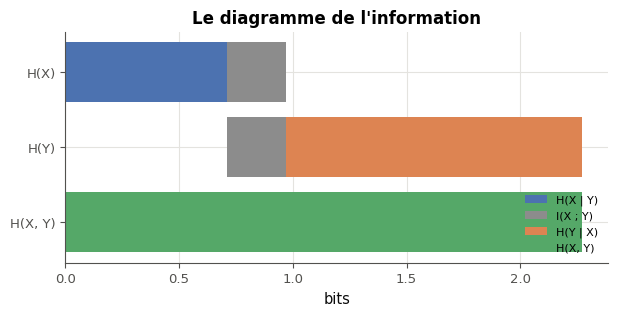

In [37]:
def draw_information_bars(ax, joint):
    """In ax, three horizontal bars, in bits: H(X) = H(X | Y) + I(X ; Y), H(Y) = I(X ; Y) + H(Y | X) shifted so that
    the two I(X ; Y) pieces are aligned, and H(X, Y); the names of the bars on the vertical axis."""
    joint = np.asarray(joint, dtype=float)
    h_xy = mymath.info.joint_entropy(joint)
    h_y_given_x = mymath.info.conditional_entropy(joint)
    h_x_given_y = mymath.info.conditional_entropy(joint.T)
    mi = mymath.info.mutual_information(joint)
    ax.barh(2, h_x_given_y, color="#4c72b0", label="H(X | Y)")
    ax.barh(2, mi, left=h_x_given_y, color="#8c8c8c", label="I(X ; Y)")
    ax.barh(1, mi, left=h_x_given_y, color="#8c8c8c")
    ax.barh(1, h_y_given_x, left=h_x_given_y + mi, color="#dd8452", label="H(Y | X)")
    ax.barh(0, h_xy, color="#55a868", label="H(X, Y)")
    ax.set_yticks([2, 1, 0], labels=["H(X)", "H(Y)", "H(X, Y)"])
    ax.set(xlabel="bits", title="Le diagramme de l'information")
    ax.legend(loc="lower right", fontsize=8)


fig, ax = plt.subplots(figsize=(7, 3))
draw_information_bars(ax, [[0.3, 0.05, 0.05], [0.1, 0.2, 0.3]])
plt.show()

**Vérifications automatiques** (sur un autre exemple ; la figure elle-même se juge à l'œil).

In [38]:
with checked("M06.23 vérifications"):
    from matplotlib.patches import Rectangle
    problems = []
    joint_t = np.array([[0.25, 0.05], [0.15, 0.15], [0.05, 0.35]])     # another example


    def entropy_t(p):
        p = np.asarray(p, dtype=float).ravel()
        p = p[p > 0]
        return float(-np.sum(p * np.log2(p)))


    hx, hy, hxy = entropy_t(joint_t.sum(axis=1)), entropy_t(joint_t.sum(axis=0)), entropy_t(joint_t)
    fig, ax = plt.subplots(figsize=(7, 3))
    try:
        created = drawn(draw_information_bars, ax, joint_t)
        fig.canvas.draw()
        labels = " ".join(t.get_text() for t in [*ax.get_yticklabels(), *ax.texts]).replace(" ", "")
        xlabel = ax.get_xlabel()
        rows = {}
        widths = [abs(patch.get_width()) for patch in ax.patches if isinstance(patch, Rectangle)]
        heights = [abs(patch.get_height()) for patch in ax.patches if isinstance(patch, Rectangle)]
        vertical = bool(widths) and max(heights) > hxy - 1e-6 and max(widths) < hxy - 1e-6
        for patch in ax.patches:
            if isinstance(patch, Rectangle) and abs(patch.get_width()) > 1e-9:
                key = round(patch.get_y() + patch.get_height() / 2, 6)
                rows.setdefault(key, []).append((patch.get_x(), patch.get_x() + patch.get_width()))
    finally:
        plt.close(fig)                                                     # only the checks below are shown here
    rows = [sorted(row) for row in rows.values()]

    def has_row(*intervals):
        return any(len(row) == len(intervals) and all(abs(a - c) < 1e-6 and abs(b - d) < 1e-6
                                                      for (a, b), (c, d) in zip(row, intervals)) for row in rows)

    if created:
        problems.append("draw_information_bars ouvre sa propre figure : dessine dans l'axe reçu")
    elif not rows:
        problems.append("il manque les barres horizontales (ax.barh)")
    elif vertical:
        problems.append("les barres doivent être horizontales : ax.barh(position, largeur, left=début), pas ax.bar")
    else:
        if not has_row((0, hxy - hy), (hxy - hy, hx)):
            problems.append("la barre de H(X) a deux morceaux : H(X | Y), de 0 à H(X | Y), puis I(X ; Y), jusqu'à H(X)")
        if not has_row((hxy - hy, hx), (hx, hxy)):
            problems.append("la barre de H(Y) commence à H(X | Y), sous le morceau I(X ; Y) de la barre de H(X), puis "
                            "continue par H(Y | X)")
        if not (has_row((0, hxy)) or has_row((0, hxy - hy), (hxy - hy, hx), (hx, hxy))):
            problems.append("la barre de H(X, Y) va de 0 à H(X, Y)")
        if not all(name in labels for name in ("H(X)", "H(Y)", "H(X,Y)")):
            problems.append("écris le nom de chaque barre sur l'axe vertical : H(X), H(Y), H(X, Y)")
        if "bit" not in xlabel.lower():
            problems.append("l'axe horizontal est en bits : écris-le (ax.set_xlabel)")
    if problems:
        print("❌ Ex M06.23 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M06.23 : les trois barres sont justes et alignées, avec leurs noms et leur unité.")

✅ Ex M06.23 : les trois barres sont justes et alignées, avec leurs noms et leur unité.


💡 On lit $H(X) = H(X \mid Y) + I(X ; Y)$ sur la première barre, $H(Y) = I(X ; Y) + H(Y \mid X)$ sur la deuxième, et $H(X, Y) = H(X \mid Y) + I(X ; Y) + H(Y \mid X)$ sur la troisième ; d'où les deux règles de la chaîne, et $I = H(X) - H(X \mid Y) = H(Y) - H(Y \mid X) = H(X) + H(Y) - H(X, Y)$. Pour des variables indépendantes, le morceau commun disparaît : les deux barres se suivent sans se chevaucher. Si $Y = X$, $H(X \mid Y) = H(Y \mid X) = 0$ et les trois barres ont la même longueur.

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §1, §2, §5 et §7. Trois erreurs à trouver, 0 log 0 calculé proprement, puis une panne à localiser en un minimum de questions.

### Ex M06.24 — Chasse à l'erreur : log en base 10, 0 log 0, KL à l'envers 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans du code les erreurs classiques sur l'entropie, la cross-entropy et la divergence KL, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §1, §2, §5 et §8 · **Parcours :** C

Des données suivent la loi `p`, un modèle la loi `q`. Un collègue a écrit six lignes, chacune avec un commentaire qui dit ce qu'elle veut calculer ; chaque ligne utilise les variables des lignes précédentes telles qu'elles **devraient** être (on suppose les lignes précédentes justes). Trois lignes ne calculent pas ce que dit leur commentaire. **Sans exécuter de code**, trouve-les.

```python
p = np.array([0.5, 0.375, 0.125, 0.0])        # the law of the data
q = np.array([0.25, 0.5, 0.125, 0.125])       # the law of the model
H_p = -np.sum(p * np.log2(p))                 # (A) the entropy of p, in bits
H_p_nats = H_p * math.log(2)                  # (B) the same entropy, in nats
H_pq = -np.sum(p * np.log10(q))               # (C) the cross-entropy H(p, q), in bits
KL = np.sum(q * np.log2(q / p))               # (D) the divergence KL(p ‖ q), in bits
info_4 = -math.log2(q[3])                     # (E) the information of the 4th outcome under the model, in bits
perplexity = 2 ** H_pq                        # (F) the perplexity of the model on the data, 2 ** H(p, q)
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) pour chacune des six lignes, de (A) à (F), la bonne valeur de ce que dit son commentaire (une liste de 6 nombres, 3 décimales).

Dans ta copie : pour chaque ligne fausse, que renvoie-t-elle (un nombre faux, `nan` ou `inf`), et comment la corriger ? Pourquoi le résultat d'une ligne fausse peut-il passer inaperçu ?

In [39]:
answer_M06_24a = "ACD"
p = np.array([0.5, 0.375, 0.125, 0.0])
q = np.array([0.25, 0.5, 0.125, 0.125])
seen = p > 0                                            # 0 log 0 counts as 0: keep the outcomes seen in the data
H_p = -np.sum(p[seen] * np.log2(p[seen]))               # (A) without the filter: 0 × (−inf) = nan
H_p_nats = H_p * math.log(2)                            # (B) correct
H_pq = -np.sum(p[seen] * np.log2(q[seen]))              # (C) log2, not log10
KL = np.sum(p[seen] * np.log2(p[seen] / q[seen]))       # (D) p in front, p / q: KL(q ‖ p) would be infinite here
info_4 = -math.log2(q[3])                               # (E) correct
perplexity = 2 ** H_pq                                  # (F) correct
answer_M06_24b = [float(value) for value in (H_p, H_p_nats, H_pq, KL, info_4, perplexity)]
print(answer_M06_24a, [round(value, 4) for value in answer_M06_24b])

ACD [1.4056, 0.9743, 1.75, 0.3444, 3.0, 3.3636]


In [40]:
wbm.record("M06.24a", "ACD",
           mistakes={"il manque une ligne fautive : refais chaque calcul avec une probabilité nulle : que vaut 0 × log₂ 0 pour NumPy ?": "CD",
                     "il manque une ligne fautive : regarde la base de chaque logarithme": "AD",
                     "il manque une ligne fautive : relis l'ordre des deux lois dans chaque formule": "AC",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABCD", "ACDE", "ACDF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais chaque calcul avec une probabilité nulle : que vaut 0 × log₂ 0 pour NumPy ?": {"BCD", "CDE", "CDF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : regarde la base de chaque logarithme": {"ABD", "ADE", "ADF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : relis l'ordre des deux lois dans chaque formule": {"ABC", "ACE", "ACF"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "C", "D"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "E", "F", "AB", "AE", "AF", "BC", "BD", "BE", "BF", "CE", "CF", "DE", "DF", "EF", "ABE", "ABF", "AEF", "BCE", "BCF", "BDE", "BDF", "BEF", "CEF", "DEF", "ABCE", "ABCF", "ABDE", "ABDF", "ABEF", "ACEF", "ADEF", "BCDE", "BCDF", "BCEF", "BDEF", "CDEF", "ABCEF", "ABDEF", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDE", "ABCDF", "ACDEF", "ABCDEF"}})
wbm.record("M06.24b", [1.4056390622295665, 0.9743147528693494, 1.75, 0.34436093777043353, 3.0, 3.363585661014858],
           decimals=3,
           mistakes={"une de tes valeurs reprend ce que calcule une ligne fausse, pas ce que dit son commentaire : "
                     "refais le calcul de chaque ligne fausse à partir de son commentaire":
                         [1.4056390622295665, 0.9743147528693494, 0.5268024924119671, 0.34436093777043353, 3.0,
                          3.363585661014858],
                     "une de tes valeurs utilise l'entropie là où le commentaire demande une autre quantité : relis "
                     "chaque commentaire":
                         [1.4056390622295665, 0.9743147528693494, 1.75, 0.34436093777043353, 3.0, 2 ** 1.4056390622295665]})

WBM_ANSWER {"hash": "406f4b9f45fb252e0215374448ec3c009c126bdd21d25bd1f2d5019a18cd2499", "id": "M06.24a", "kind": "str", "mistakes": {"01e932ab9822b2d115bb52634c0a30206d3eb4a101c5cda31abc72befac69112": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "10a0d1ca442c34050f3568fcdca2d34374ee6f50850574db704b974c982b308a": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "12aecc9c870174050c0771fadd35b2d722cbc79e648012ef20452a079f8cbb40": "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple", "161f92050b3c1a89208fd7ea3c30e43786fec871f124ade6fe22a782d42cf69a": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "1cc0ff310d71a60feb9e0f1e265e2dcfd8a848b2860f8bfd267e614b862ce324": "une des lignes que tu cites est correcte, et il manque une ligne fautive

💡 (A) $0 \times \log_2 0$ vaut `nan` pour NumPy ($0 \times (-\infty)$) : la somme est `nan` ; il faut ne garder que les probabilités non nulles (ou `xlogy`, M06.25). La bonne valeur : $0{,}5 + 0{,}375\log_2\frac{8}{3} + 0{,}375 \approx 1{,}406$ bit. (C) `log10` donne la cross-entropy en « bans », $1{,}75 \log_{10} 2 \approx 0{,}527$ : la bonne valeur est $H(p, q) = 0{,}5 \times 2 + 0{,}375 \times 1 + 0{,}125 \times 3 = 1{,}75$ bit. (D) Les deux lois sont échangées : c'est $\mathrm{KL}(q \,\|\, p)$, infinie ici car $q$ donne une probabilité à la 4ᵉ issue et $p$ non ; $\mathrm{KL}(p \,\|\, q) = 1{,}75 - 1{,}406 \approx 0{,}344$. (B), (E) et (F) sont justes : $1{,}406 \ln 2 \approx 0{,}974$ nat, $-\log_2 0{,}125 = 3$ bits, $2^{1{,}75} \approx 3{,}364$. Une ligne fausse qui renvoie un nombre plausible, comme (C), passe facilement inaperçue ; `nan` et `inf` se voient.

### Ex M06.25 — Calculer 0 log 0 proprement (`scipy.special.xlogy`) 🛠️ ★ ⏱️ 10 min
**Objectif :** calculer d'un coup les entropies des lignes d'une loi jointe, sans `nan` ni avertissement quand des probabilités sont nulles, avec la fonction de SciPy faite pour cela.  
**Prérequis :** fiche §2 et §3 ; Ex M06.24 · **Parcours :** C

`p * np.log2(p)` vaut `nan` dès qu'une probabilité est nulle ($0 \times (-\infty)$), avec un avertissement. Le filtre `p[p > 0]` règle le problème pour un vecteur, mais il aplatit le tableau : il ne convient plus quand on veut une entropie **par ligne**. SciPy a une fonction faite pour cela : `scipy.special.xlogy(x, y)` calcule $x \ln y$ case par case, et renvoie 0 quand $x = 0$, même si $y = 0$, sans avertissement.

Écris `row_entropies(joint, base=2)`, qui renvoie, pour une loi jointe `joint` dont aucune ligne n'est nulle, le tableau NumPy des entropies $H(Y \mid X = x)$ de ses lignes, chacune divisée par sa somme (fiche §3) : avec `xlogy`, sans boucle ni filtre (`keepdims=True` garde la forme d'une somme par ligne, `axis=1` somme chaque ligne). La vérification compare ta fonction à un calcul de référence sur plusieurs tableaux, dont des probabilités nulles, vérifie qu'elle n'émet aucun avertissement et qu'elle utilise `xlogy` sans boucle ni filtre ; puis elle calcule `row_entropies(T25)` pour `T25 = [[0.2, 0, 0.1], [0.14, 0.2, 0.06], [0, 0.3, 0]]` (une liste de 3 nombres, 4 décimales).

Dans ta copie : pourquoi la convention $0 \log 0 = 0$ est-elle la bonne (quelle est la limite de $x \ln x$ quand $x$ tend vers 0 ?) ? Calcule $H(Y \mid X)$ pour `T25` à partir de ta liste. Pourquoi la troisième ligne a-t-elle une entropie nulle ?

In [41]:
from scipy.special import xlogy


def row_entropies(joint, base=2):
    """The entropies H(Y | X = x) of the rows of joint, each divided by its sum, with xlogy: no loop, no filter."""
    table = np.asarray(joint, dtype=float)
    conditional = table / table.sum(axis=1, keepdims=True)
    return -xlogy(conditional, conditional).sum(axis=1) / math.log(base) + 0.0


T25 = [[0.2, 0, 0.1], [0.14, 0.2, 0.06], [0, 0.3, 0]]
print(row_entropies(T25), "· H(Y | X) =", float(np.sum(np.sum(T25, axis=1) * row_entropies(T25))))

[0.91829583 1.44064545 0.        ] · H(Y | X) = 0.8517469300624854


In [42]:
wbm.record("M06.25", [0.9182958340544894, 1.440645449615346, 0.0], decimals=4,
           mistakes={"la fonction donne des bits par défaut (base=2) : divise par ln 2":
                         [0.6365141682948128, 0.9985793315873919, 0.0],
                     "divise d'abord chaque ligne par sa somme : les entropies portent sur les lois conditionnelles":
                         [0.7965784284662087, 1.1050294178010835, 0.5210896782498619]})

WBM_ANSWER {"decimals": 4, "element_coarse": [["bb199c8a1a5768149847def8b8dc4f4642a15f63cf3a8c8fa60ea4d8489fa4d5"], ["52121f88b8c26bb180d16b0bf85753929882a916e33415aafc82a86bae1854ec"], ["30753c26a6f1f81de37a2e4c2872928a41f365c123305b3aeb9de43846a02090"]], "element_coarse_any": [["8e7084fe621d771dad62d3438be7901fedc24519eb0571e2dbff86856819a5f3", "7f823959d07fc1ff596f7d94616e05d8085f485bcc790f0317a0908352bd17d2", "f0d215b20586bb59f811a2ec5541825648efccfd66d8e8b6b756e3e31112a983"], ["d47cde5d252ff1303ebafbdf5f03bb9656ed8bbf32b9ac8852bd9a51e55ea2bf", "c80f603c9db20efc0ef89e05ec771e7de894c395bf13d0a66d801ce1c4e27a71", "43443a11affc6eefdde87dbbc6e189cdc74d4fbf5707af1c4e3b4d8461af7b20"], []], "element_hashes": ["ca27231e30c56d310336b06e9219bbe0f7f76630cb38c6c92496a5d01555a563", "f12e043ae10f610393d5b1feb556d238eec3875e23ce124c635058f2c9d45a2b", "91b0560606d537a51efadde77162b4f3e601a87d9cae67f7ecc66133a5f03fae"], "hash": "69218e6d9ea380c2bd3405a03d82c972ad3840aa9446327cdadeb8e64b3d515a", "id

In [43]:
with checked("M06.25 vérifications"):
    import ast
    import inspect
    import textwrap
    import warnings
    problems = []
    tables_t = [[[0.5, 0.0], [0.2, 0.3]], [[0.1, 0.1, 0.0], [0.0, 0.0, 0.8]], [[0.25], [0.75]],
                [[0.05, 0.15, 0.2], [0.3, 0.1, 0.2]]]
    for table in tables_t:
        array_t = np.asarray(table, dtype=float)
        expected = []
        for row in array_t:
            law = row[row > 0] / row.sum()
            expected.append(float(-np.sum(law * np.log2(law))) + 0.0)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            got = row_entropies(table)
        if got is None:
            problems.append("row_entropies ne renvoie rien : il manque return")
            break
        if caught:
            problems.append(f"row_entropies({table}) émet un avertissement ({caught[0].category.__name__}) : xlogy "
                            "n'en émet pas, même pour une probabilité nulle")
            break
        if not isinstance(got, np.ndarray) or got.dtype != float:
            problems.append(f"renvoie un tableau NumPy de flottants, pas un {type(got).__name__}")
            break
        if got.shape != (len(table),) or not np.allclose(got, expected, atol=1e-12):
            problems.append(f"row_entropies({table}) devrait valoir {np.round(expected, 6).tolist()}, pas "
                            f"{np.round(np.asarray(got, dtype=float), 6).tolist()} : chaque ligne divisée par sa somme, "
                            "puis son entropie")
            break
    if not problems:
        nats_t = row_entropies([[0.2, 0.3, 0.5]], base=math.e)
        if not np.allclose(nats_t, [-sum(v * math.log(v) for v in (0.2, 0.3, 0.5))], atol=1e-12):
            problems.append("avec base=math.e, le résultat est en nats : divise par ln(base)")
    if not problems:
        try:
            source_t = inspect.getsource(row_entropies)
        except (OSError, TypeError):
            source_t = ""
        try:
            tree_t = ast.parse(textwrap.dedent(source_t)) if source_t else None
        except SyntaxError:
            tree_t = None
        if tree_t is not None:
            nodes_t = list(ast.walk(tree_t))
            names_t = ({node.id for node in nodes_t if isinstance(node, ast.Name)}
                       | {node.attr for node in nodes_t if isinstance(node, ast.Attribute)})
            loop_t = any(isinstance(node, (ast.For, ast.While, ast.comprehension)) for node in nodes_t)
            mask_t = any(isinstance(node, ast.Subscript)
                         and any(isinstance(part, ast.Compare) for part in ast.walk(node.slice)) for node in nodes_t)
            if "xlogy" not in names_t:
                problems.append("l'exercice demande xlogy : sers-t'en pour les termes p log p")
            elif loop_t or mask_t:
                problems.append("ni boucle ni filtre : xlogy s'occupe des probabilités nulles, et NumPy de toutes les "
                                "lignes à la fois (axis=1)")
    if problems:
        print("❌ Ex M06.25 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M06.25 : row_entropies est juste, avec xlogy, sans boucle ni avertissement.")

✅ Ex M06.25 : row_entropies est juste, avec xlogy, sans boucle ni avertissement.


💡 $x \ln x \to 0$ quand $x \to 0^+$ (avec $x = \frac{1}{t}$, $x \ln x = -\frac{\ln t}{t}$ tend vers 0, R6) : une issue impossible n'apporte rien à l'entropie, d'où la convention. Les lignes de `T25`, divisées par leur somme, sont $(\frac{2}{3}, 0, \frac{1}{3})$, $(0{,}35 ;\ 0{,}5 ;\ 0{,}15)$ et $(0, 1, 0)$ : leurs entropies valent environ 0,9183, 1,4406 et 0 (la troisième loi est certaine). $H(Y \mid X) \approx 0{,}3 \times 0{,}9183 + 0{,}4 \times 1{,}4406 \approx 0{,}8517$.

### Ex M06.26 — Défi : localiser une panne parmi 100 serveurs en un minimum de questions 🏆 ★★★ ⏱️ 25 min
**Objectif :** concevoir une stratégie de questions par oui ou non qui approche l'entropie, pour une loi uniforme et pour une loi inégale.  
**Prérequis :** fiche §2 et §7 · **Parcours :** C

Cent serveurs, numérotés de 1 à 100, sont branchés à la suite ; l'un d'eux est en panne. Un test indique si la panne est sur l'un des serveurs 1 à $t$ (« oui » ou « non ») : chaque test est une question. Chaque suite de réponses est un mot d'un code préfixe binaire (fiche §7) : en moyenne, il faut donc au moins $H$ questions, où $H$ est l'entropie de la loi du serveur en panne. Des questions de cette forme, qui coupent toujours la liste en deux morceaux, permettent toujours de faire moins de $H + 2$ en moyenne, et souvent bien mieux… à condition de bien les choisir.

Écris `locate_fault(is_at_most, probs)`, qui trouve le serveur en panne en appelant `is_at_most(t)` (qui renvoie `True` si la panne est sur l'un des serveurs 1 à `t`), et renvoie son numéro. `probs[k]` est la probabilité que la panne soit sur le serveur `k + 1` : ta stratégie peut s'en servir. **Les objectifs** :
- quand tous les serveurs ont la même probabilité : au plus 7 questions pour chaque serveur, et au plus 6,72 en moyenne ;
- quand la probabilité du serveur $n$ est proportionnelle à $\frac{1}{n}$ (les premiers, les plus anciens, tombent plus souvent en panne) : au plus 5,50 questions en moyenne, pondérée par les probabilités.

La vérification essaie ta fonction sur les 100 serveurs, pour les deux lois, en comptant les questions. Elle vérifie aussi `bound_26`, l'entropie en bits de la seconde loi, que tu calcules (4 décimales) : le nombre moyen de questions ne peut pas descendre en dessous.

Dans ta copie : pourquoi 6,72 est-il le mieux possible pour la loi uniforme (combien de serveurs peut-on distinguer avec 6 questions ? avec 7 ?) ? Pourquoi couper la liste en deux moitiés de même longueur ne suffit-il pas pour la seconde loi ? Compare ton score à `bound_26`.

In [44]:
PROBS_UNIFORM_26 = np.full(100, 0.01)                      # probs[k]: the probability of the server k + 1
PROBS_AGE_26 = 1 / np.arange(1, 101)
PROBS_AGE_26 = PROBS_AGE_26 / PROBS_AGE_26.sum()               # the probability of server n is proportional to 1/n

In [45]:
def locate_fault(is_at_most, probs):
    """The faulty server (1 to len(probs)), found with tests is_at_most(t) -> bool; probs[k] is the probability of k + 1."""
    lo, hi = 1, len(probs)                                   # the faulty server is in lo..hi
    cumulative = np.concatenate([[0.0], np.cumsum(probs)])   # cumulative[k] = P(faulty server <= k)
    while lo < hi:
        middle = (cumulative[lo - 1] + cumulative[hi]) / 2   # half of the probability left
        candidates = np.arange(lo, hi)
        t = int(candidates[np.argmin(np.abs(cumulative[candidates] - middle))])
        if is_at_most(t):
            hi = t
        else:
            lo = t + 1
    return lo


p_26 = PROBS_AGE_26
bound_26 = float(-np.sum(p_26 * np.log2(p_26)))
print("entropy of the 1/n law:", bound_26, "· of the uniform law:", math.log2(100))

entropy of the 1/n law: 5.310239799410162 · of the uniform law: 6.643856189774724


In [46]:
wbm.record("M06.26", 5.310239799410162, decimals=4,
           mistakes={"la question demande des bits : log₂, pas ln": 3.680777745058364,
                     "c'est l'entropie de la loi uniforme : calcule celle de PROBS_AGE_26": 6.643856189774724})

WBM_ANSWER {"coarse_any": {"0": ["73d949b4e297ca4b141bc857fb40697f14f4abee7f4759288b5f4e1d932adf81"]}, "coarser": {"1": ["7e0be70f808edd915f1bfcdb49279a15d9750964be759622ad99dc155c34dfb8"], "2": ["080a163a9c8c2322da6a17767005ac3f58d3a751f32b69cfc35cabb70a368073"]}, "decimals": 4, "hash": "e0ea8fb94018e5874dd478e2cb2f92b3609ca73a5ba3b2f35cd97f03570ae93a", "hash_coarse": "0406f34c51e747f6cc77afd8e0e1968d68f60c3e903b184db965aa01cca6800d", "id": "M06.26", "kind": "float", "magnitude": 0, "mistakes": {"28eb19c1249aaae8fafce7ae5be46daeca4de0b34669658cfeff7a1c3dcb79e2": "la question demande des bits : log₂, pas ln", "5ad339f7100fb5b8799711345e30c60d8c59253a5002fe36581c171a1ff06ce4": "c'est l'entropie de la loi uniforme : calcule celle de PROBS_AGE_26"}, "sign": 1}
📝 Ex M06.26 : réponse enregistrée (float, 4 décimales).


In [47]:
with checked("M06.26 défi"):
    problems, results = [], {}
    for law_name, probs_t in [("uniforme", PROBS_UNIFORM_26), ("en 1/n", PROBS_AGE_26)]:
        counts_t = []
        for faulty in range(1, 101):
            questions = []

            def is_at_most(t, faulty=faulty, questions=questions):
                questions.append(t)
                if len(questions) > 200:
                    raise RuntimeError("plus de 200 questions : ta stratégie tourne en rond")
                return faulty <= t

            try:
                got = locate_fault(is_at_most, list(probs_t))
            except NotImplementedError:
                raise
            except Exception as exc:  # noqa: BLE001
                problems.append(f"loi {law_name}, serveur {faulty} : locate_fault lève {type(exc).__name__} ({exc})")
                break
            if got != faulty:
                problems.append(f"loi {law_name} : pour une panne sur le serveur {faulty}, locate_fault renvoie {got!r}")
                break
            counts_t.append(len(questions))
        if problems:
            break
        results[law_name] = (max(counts_t), float(np.dot(probs_t, counts_t)))
    if problems:
        print("❌ Ex M06.26 : " + problems[0] + ".")
    else:
        worst_u, mean_u = results["uniforme"]
        mean_a = results["en 1/n"][1]
        print(f"loi uniforme : {worst_u} questions au plus, {mean_u:.3f} en moyenne · loi en 1/n : {mean_a:.3f} en "
              "moyenne")
        failures = []
        if worst_u > 7:
            failures.append("plus de 7 questions pour un des serveurs, avec la loi uniforme")
        if mean_u > 6.72 + 1e-9:
            failures.append("plus de 6,72 questions en moyenne avec la loi uniforme")
        if mean_a > 5.50 + 1e-9:
            failures.append("plus de 5,50 questions en moyenne avec la loi en 1/n : sers-toi des probabilités pour "
                            "choisir chaque question")
        if failures:
            print("❌ Ex M06.26 : objectif pas encore atteint : " + " ; ".join(failures) + ".")
        else:
            print("✅ Ex M06.26 : défi réussi, les deux objectifs sont atteints.")

loi uniforme : 7 questions au plus, 6.720 en moyenne · loi en 1/n : 5.369 en moyenne
✅ Ex M06.26 : défi réussi, les deux objectifs sont atteints.


💡 Avec 6 questions, on distingue au plus $2^6 = 64$ serveurs, avec 7, $2^7 = 128$ : pour 100 serveurs, il faut 7 questions pour certains ; au mieux, 28 serveurs en demandent 6 et 72 en demandent 7, soit $\frac{28 \times 6 + 72 \times 7}{100} = 6{,}72$ en moyenne (l'entropie vaut $\log_2 100 \approx 6{,}64$). Pour la loi en $\frac{1}{n}$, couper la liste en deux moitiés de même longueur pose autant de questions pour le serveur 1, très probable, que pour le 100, très rare : 6,6 à 6,8 en moyenne. Couper la **probabilité** restante en deux parts aussi égales que possible donne environ 5,37 questions en moyenne, tout près de l'entropie, environ 5,31 bits : les serveurs probables reçoivent des mots courts, comme dans un bon code.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer l'information d'un événement et l'entropie d'une loi, en bits et en nats ?
2. Sais-tu calculer des entropies conjointe et conditionnelle et une information mutuelle à partir d'un tableau, et dire ce que mesure chacune ?
3. Sais-tu calculer une cross-entropy et une divergence KL, les lire en bits perdus, et dire pourquoi la KL est positive (Jensen) ?
4. Sais-tu dire si des longueurs de code sont possibles (Kraft), et comparer la longueur moyenne d'un code à l'entropie ?

**La suite** : le chapitre 6 de workbookIA (entropie, cross-entropy, KL, codes), puis CP1, l'examen blanc de la partie I.